# Семинар 2

**Данные:** PBMC 3k (периферическая кровь человека, 10x Genomics)

В первом семинаре мы получили матрицу экспрессии, провели QC, нормализацию, выбрали 2000 высоковариабельных генов (HVG) и построили PCA. Теперь мы хотим ответить на два разных вопроса:

1. **Какие клетки образуют группы?** Для этого строим граф ближайших соседей и применяем Leiden.
2. **Как показать тысячи клеток на одном двумерном графике?** Для этого используем UMAP или t-SNE.

> **Главное различие:** Leiden определяет кластеры **на графе соседства**, построенном по координатам PCA. UMAP и t-SNE нужны прежде всего для **визуализации**, а не для установления кластеров.

## 0. Подготовка окружения

Можно продолжить работу в окружении `sc_pbmc` из первого семинара. Для Leiden нужны **`leidenalg` и `python-igraph`**

```bash
mamba create -n sc_pbmc -c conda-forge \
    python=3.11 "scanpy>=1.11,<2" scikit-misc leidenalg python-igraph \
    umap-learn scikit-learn pandas numpy scipy matplotlib \
    jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Если окружение уже создано, достаточно:

```bash
mamba activate sc_pbmc
mamba install -c conda-forge leidenalg python-igraph umap-learn scikit-learn -y
```


In [ ]:
pip install scanpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 52.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 94.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.3 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [scanpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [ ]:
pip install leidenalg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 20.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 35.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [leidenalg]


In [ ]:
from pathlib import Path
import scanpy as sc
import leidenalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 0.1. Продолжаем первый семинар на тех же данных PBMC 3k

- Если `data/pbmc3k_after_pca.h5ad` уже существует, загрузим готовую обработанную матрицу.
- Иначе прочитаем исходную матрицу из `data/filtered_gene_bc_matrices/hg19/` (папка из предыдущего занятия). Если её нет, Scanpy скачает PBMC 3k из своей коллекции данных и мы повторим **те же** пороги QC, HVG и PCA.

Исходные данные: [10x Genomics PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0). Функция загрузки: [`sc.datasets.pbmc3k`](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html).

In [ ]:
!mkdir -p data
!wget -q http://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -O data/pbmc3k_filtered_gene_bc_matrices.tar.gz
!tar -xzf data/pbmc3k_filtered_gene_bc_matrices.tar.gz -C data
!ls data/filtered_gene_bc_matrices/hg19

barcodes.tsv  genes.tsv  matrix.mtx


In [ ]:
cache = Path("data/pbmc3k_after_pca.h5ad")
raw_folder = Path("data/filtered_gene_bc_matrices/hg19")


adata = sc.read_10x_mtx(raw_folder, var_names="gene_symbols", make_unique=True)

# adata = sc.datasets.pbmc3k()

In [ ]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [ ]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500) &
    (adata.obs["pct_counts_mt"] < 5)
].copy()


In [ ]:
adata.layers["counts"] = adata.X.copy()

In [ ]:
!pip install scikit-misc

In [ ]:
sc.pp.highly_variable_genes(
    adata, layer="counts", flavor="seurat_v3", n_top_genes=2000
)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

# 1. Повторение PCA

В первом семинаре каждой клетке сопоставили вектор экспрессии генов. PCA заменяет исходные признаки координатами в новом базисе:

$$
\mathbf{x}_i=(PC_{i1},PC_{i2},\dots,PC_{ip})\in\mathbb{R}^{p}.
$$

В `adata.obsm["X_pca"]` каждая **строка соответствует клетке**, каждый **столбец — компоненте PCA**.

Евклидово расстояние между клетками $i$ и $j$ в пространстве первых $p$ компонент:

$$
d(i,j)=\left\|\mathbf{x}_i-\mathbf{x}_j\right\|_2
=\sqrt{\sum_{r=1}^{p}\left(PC_{ir}-PC_{jr}\right)^2}.
$$


In [ ]:
X_pca = adata.obsm["X_pca"]
print("Первые 5 клеток, первые 5 координат PCA:")
display(pd.DataFrame(X_pca[:5, :5], index=adata.obs_names[:5],
                     columns=[f"PC{i}" for i in range(1, 6)]))

Первые 5 клеток, первые 5 координат PCA:


,PC1,PC2,PC3,PC4,PC5
AAACATACAACCAC-1,-4.729656,-0.732485,-1.319631,0.310005,-0.847269
AAACATTGAGCTAC-1,-0.771727,7.029477,4.317773,-1.829984,-1.793581
AAACATTGATCAGC-1,-3.747784,-2.741884,-2.263518,-3.970395,-1.300419
AAACCGTGCTTCCG-1,13.714365,0.483030,1.592937,-0.528195,1.163329
AAACCGTGTATGCG-1,-3.042009,-4.998953,7.369839,5.631863,1.837182


# 2. От точек к графу: kNN

**Граф** — это набор вершин и рёбер. В нашей задаче:

- вершина = одна клетка;
- ребро $i\to j$ = клетка $j$ входит в число $k$ ближайших соседей клетки $i$;
- вес ребра = численная оценка близости клеток.

Сначала алгоритм ищет **kNN — k nearest neighbors**. Это отношение в общем случае **направленное**: клетка B может входить в 2 ближайших соседа A, но клетка A может не входить в 2 ближайших соседа B.

Для графовой кластеризации обычно используют **ненаправленный взвешенный граф**. Простейшая симметризация бинарного графа — $A_{ij}^{\mathrm{sym}}=\max(A_{ij},A_{ji})$.

В Scanpy при `method="umap"` расчёт **весов** устроен сложнее: используются локально масштабированные степени принадлежности к соседству с последующим объединением направленных связей. Это **не** просто обратное евклидово расстояние.


### kNN на реальных клетках

В Scanpy используется **двухэтапная процедура**:

1. Найти ближайших соседей по координатам первых 30 PC (`n_pcs=30`).
2. По этим соседям вычислить веса связей между клетками (`connectivities`).

**Где хранятся результаты?**

| Поле AnnData | Что означает |
|---|---|
| `adata.obsm["X_pca"]` | Координаты клеток в PCA |
| `adata.obsp["distances"]` | Разреженная матрица найденных расстояний |
| `adata.obsp["connectivities"]` | Разреженная, симметричная матрица весов связей |
| `adata.uns["neighbors"]` | Параметры построения графа и ссылки на матрицы |

**Важно:** `n_neighbors=15` — локальный параметр поиска соседей. После симметризации у вершины может оказаться **больше 15 ненулевых связей**.

In [ ]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    metric="euclidean",
    method="umap",
    random_state=42,
)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'

In [ ]:
G = adata.obsp["connectivities"].tocsr()
D = adata.obsp["distances"].tocsr()

In [ ]:
print("Граф connectivities:", G.shape, "ненулевых элементов:", G.nnz)

print("Матрица distances:", D.shape, "ненулевых элементов:", D.nnz)

Граф connectivities: (2638, 2638) ненулевых элементов: 58162
Матрица distances: (2638, 2638) ненулевых элементов: 36932


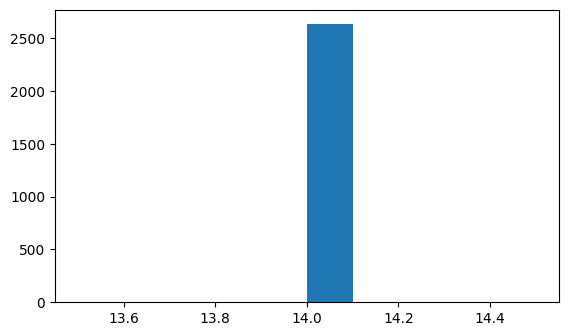

Минимум / медиана / максимум степеней: 14 14.0 14


In [ ]:
degree = np.asarray((D > 0).sum(axis=1)).ravel()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(degree, bins=10)
plt.show()

print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

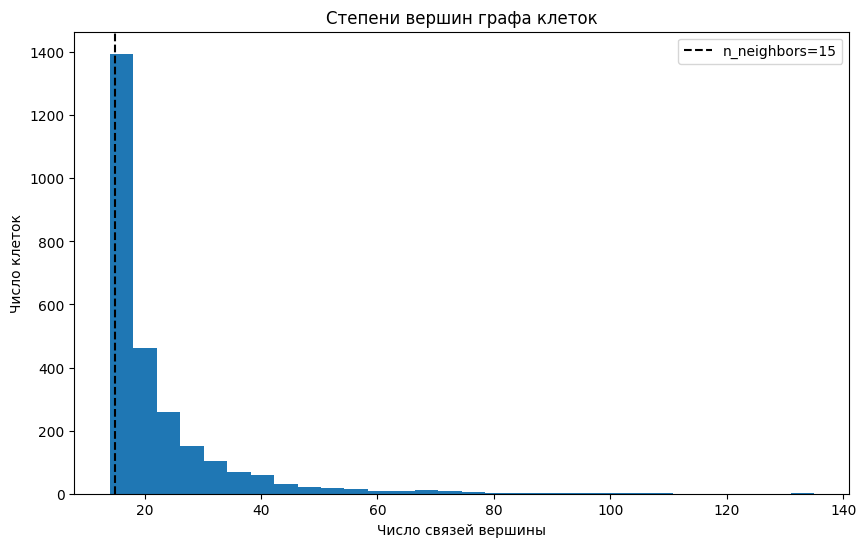

Число компонент связности: 1
Минимум / медиана / максимум степеней: 14 18.0 135


In [ ]:
from scipy.sparse.csgraph import connected_components
degree = np.asarray((G > 0).sum(axis=1)).ravel()
components, labels_components = connected_components(G, directed=False)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(degree, bins=30)
ax.axvline(15, ls="--", color="black", label="n_neighbors=15")
ax.set(xlabel="Число связей вершины", ylabel="Число клеток",
       title="Степени вершин графа клеток")
ax.legend()
plt.show()
print("Число компонент связности:", components)
print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

# 3. Графовая кластеризация: Louvain → Leiden

**Кластеризация** — разбиение объектов на группы. Но «хорошая группа» должна иметь математическое определение.

- В методах типа k-means группа — набор точек, близких к общему центроиду.
- В графовых методах **сообщество** — группа вершин, которые связаны друг с другом сильнее, чем ожидалось бы при случайном соединении вершин по подходящей нулевой модели.

## 3.1. Модулярность: что оптимизирует алгоритм

Рассмотрим **ненаправленный граф** с матрицей весов $A=(A_{ij})$. Обозначим:

- $A_{ij}$ — вес ребра между вершинами $i$ и $j$;
- $k_i=\sum_j A_{ij}$ — взвешенная степень вершины $i$;
- $2m=\sum_i k_i$ — сумма весов рёбер, посчитанных по двум концам;
- $c_i$ — номер сообщества вершины $i$;
- $\mathbf{1}(c_i=c_j)$ равен единице, когда вершины в одной группе.

Одна из функций качества разбиения — **модулярность с параметром разрешения $\gamma$**:

$$
Q_{\gamma}=\frac{1}{2m}\sum_{i,j}
\left(A_{ij}-\gamma\frac{k_i k_j}{2m}\right)
\mathbf{1}(c_i=c_j).
$$

**Как понимать формулу:**

- $A_{ij}$ — наблюдаемый вес связи;
- $k_i k_j/(2m)$ — ожидаемый вес связи в модели случайного графа, сохраняющей ожидаемые степени вершин;
- в сумму попадают только пары вершин **из одной группы**;
- алгоритм пытается найти разбиение с **высоким значением $Q_\gamma$**.

$\gamma$ отвечает за масштаб: при большем $\gamma$ крупные сообщества сильнее «штрафуются», поэтому на практике часто появляются более мелкие кластеры. **Но число кластеров не обязано расти строго монотонно** из-за устройства графа и эвристической оптимизации.

## 3.2. Louvain и Leiden: чем они отличаются

**Louvain (2008):**

1. Стартует с отдельных сообществ (каждая вершина сама по себе).
2. По очереди переносит вершины между соседними сообществами, если растёт функция качества.
3. Объединяет сообщества в новые супервершины и повторяет оптимизацию.

**Проблема:** в отдельных случаях найденное сообщество может иметь плохую внутреннюю связность или даже быть несвязным.

**Leiden (2019)** добавляет **этап уточнения (refinement)** сообщества до агрегации. В результате алгоритм устраняет известную проблему несвязных сообществ Louvain и при сходимости предоставляет более сильные гарантии внутренней связности. Это **не означает**, что любой кластер Leiden биологически однороден.


Статья: [Traag, Waltman & van Eck, 2019 — From Louvain to Leiden](https://doi.org/10.1038/s41598-019-41695-z).

## 3.3. Leiden на PBMC 3k

Запустим Leiden несколько раз на **одном и том же графе**. Вызовы не используют координаты UMAP.

/tmp/ipykernel_14659/1703150331.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
/tmp/ipykernel_14659/1703150331.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1.0, key_added="lei

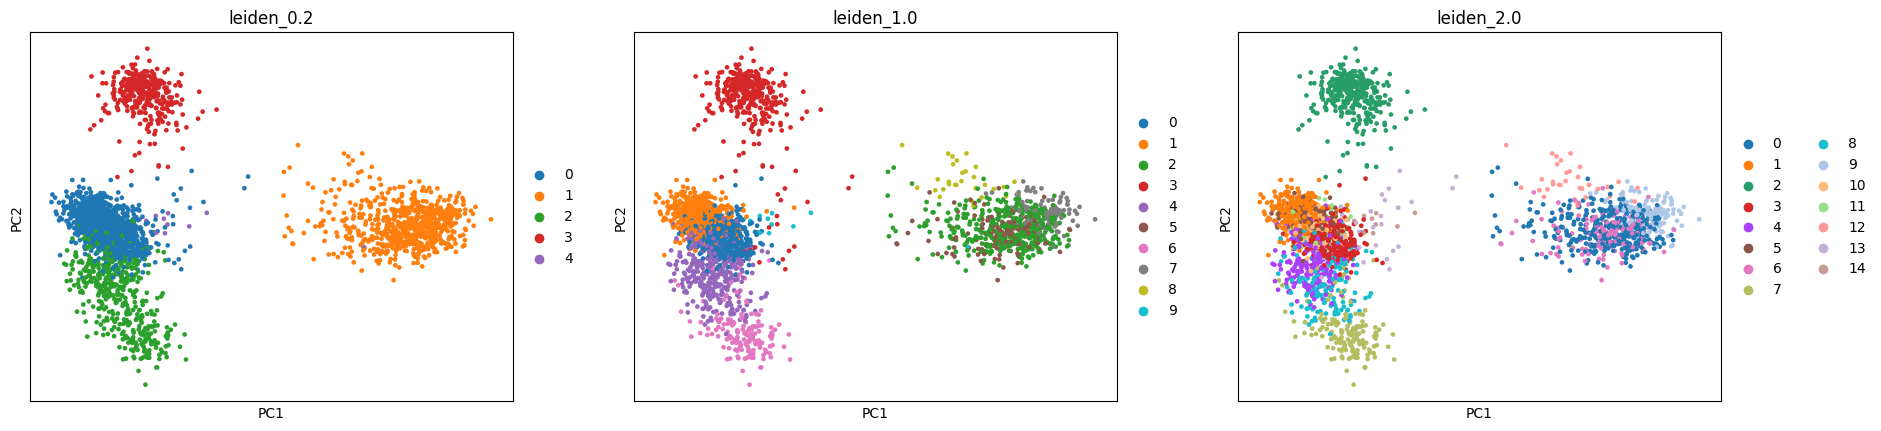

leiden_1.0
0    548
1    541
2    378
3    360
4    349
5    157
6    156
7    107
8     30
9     12
Name: count, dtype: int64


<Axes: xlabel='leiden_1.0'>

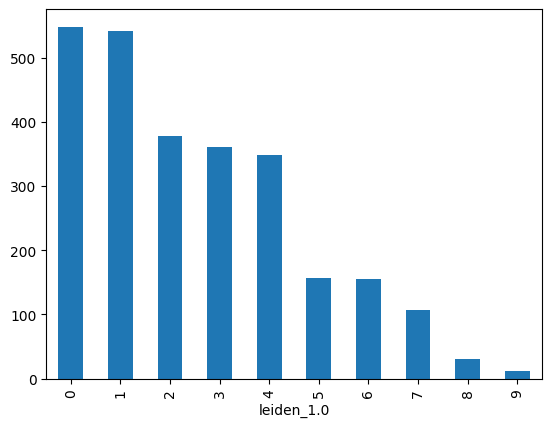

In [ ]:
sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0")
sc.tl.leiden(adata, resolution=2.0, key_added="leiden_2.0")

sc.pl.pca(
    adata,
    color=["leiden_0.2", "leiden_1.0", "leiden_2.0"],
    ncols=3
)
# Посмотрим, сколько получилось кластеров
print(adata.obs["leiden_1.0"].value_counts())
adata.obs["leiden_1.0"].value_counts().sort_index().plot.bar()

# 4. Переход из 30 измерений в два: t-SNE и UMAP

## 4.1. t-SNE: сохраняем вероятности соседства

Идея t-SNE: описать, насколько клетка $j$ является соседом клетки $i$, **вероятностью**, а затем подобрать на плоскости такую картинку, чтобы отношения соседства были похожими.

В высокоразмерном пространстве PCA условные вероятности определяются расстояниями:

$$
p_{j\mid i}=\frac{\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_j\|^2}{2\sigma_i^2}\right)}
{\sum_{k\ne i}\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_k\|^2}{2\sigma_i^2}\right)},\quad p_{i\mid i}=0.
$$

Далее строятся симметричные $p_{ij}=(p_{j\mid i}+p_{i\mid j})/(2n)$.

На двумерной карте используются тяжёлые хвосты распределения Стьюдента:

$$
q_{ij}=\frac{(1+\|\mathbf y_i-\mathbf y_j\|^2)^{-1}}
{\sum_{k\ne \ell}(1+\|\mathbf y_k-\mathbf y_\ell\|^2)^{-1}}.
$$

Подбираем координаты $\mathbf y_i$, минимизируя **KL-дивергенцию**:

$$
D_{\mathrm{KL}}(P\|Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$

**Смысл:** большие $p_{ij}$ «требуют», чтобы на карте $q_{ij}$ тоже были большими. Тяжёлые хвосты помогают разнести точки, которые не являются соседями.

`perplexity` управляет эффективным масштабом локального соседства: $\operatorname{Perp}(P_i)=2^{H(P_i)}$, где энтропия считается с логарифмом по основанию 2. Это **не точное число соседей** и не число кластеров.

## 4.2. UMAP: сохраняем взвешенное локальное соседство

UMAP начинает с соседей, строит **взвешенный граф** локального соседства и ищет координаты $\mathbf y_i$ на плоскости, при которых локальные связи остаются похожими.

В упрощённой записи направленные веса близости оцениваются как

$$
w_{j\mid i}=\exp\left[-\frac{\max\{0,d(i,j)-\rho_i\}}{\sigma_i}\right],
$$

где $\rho_i$ — локальное расстояние до ближайшего ненулевого соседа, $\sigma_i$ — локальный масштаб. Вес может затем объединяться с обратным $w_{i\mid j}$ по правилу

$$
w_{ij}=w_{j\mid i}+w_{i\mid j}-w_{j\mid i}w_{i\mid j}.
$$

На плоскости близость приближается функцией вида

$$
\hat w_{ij}=\frac{1}{1+a\|\mathbf y_i-\mathbf y_j\|^{2b}},
$$

где $a,b$ зависят от настроек формы кривой. **Идея функции потерь** — кросс-энтропия между весами связей исходного графа и весами на плоскости:

$$
\mathcal L=-\sum_{i<j}\left[
 w_{ij}\log\hat w_{ij}+(1-w_{ij})\log(1-\hat w_{ij})\right].
$$

Реальная оптимизация использует приближения, включая отрицательное семплирование несоседних пар. Формула выше описывает **математическую цель**, а не буквальный полный перебор всех пар в каждой итерации.

Параметры:

- **`n_neighbors`** (в `sc.pp.neighbors`) определяет масштаб исходных локальных отношений.
- **`min_dist`** (в `sc.tl.umap`) регулирует, насколько плотно точки могут располагаться на карте.
- **`random_state`** задаёт воспроизводимый случайный старт/другие случайные шаги алгоритма.

## Полезно посмотреть
* https://github.com/NikolayOskolkov/HowUMAPWorks/blob/master/HowUMAPWorks.ipynb   
* https://pair-code.github.io/understanding-umap/

# 5.Leiden + UMAP + t-SNE

**Цель:** выполнить обе визуализации для **одних и тех же клеток и одних и тех же меток Leiden**. Только так можно корректно сравнивать полученные картинки.

`sc.tl.umap()` использует уже построенный граф соседства. `sc.tl.tsne()` ниже явно использует первые 30 PC.

In [ ]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)

sc.tl.tsne(adata, use_rep="X_pca", n_pcs=30, perplexity=30, random_state=42)

In [ ]:
print("UMAP:", adata.obsm["X_umap"].shape,
      "t-SNE:", adata.obsm["X_tsne"].shape)

UMAP: (2638, 2) t-SNE: (2638, 2)


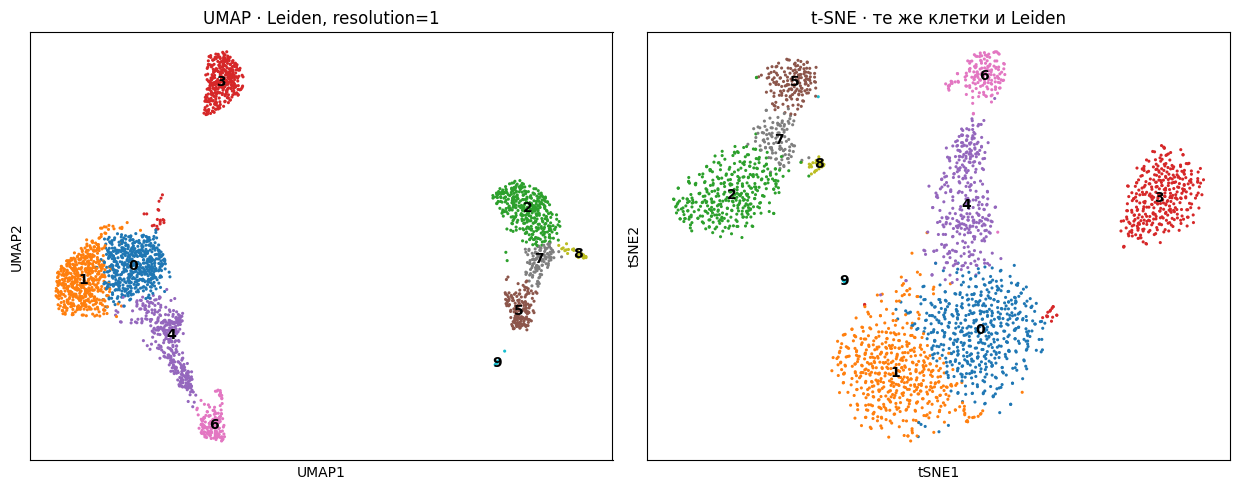

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
sc.pl.umap(adata, color="leiden_1.0", legend_loc="on data",
           title="UMAP · Leiden, resolution=1", ax=axes[0], show=False, size=20)
sc.pl.tsne(adata, color="leiden_1.0", legend_loc="on data",
           title="t-SNE · те же клетки и Leiden", ax=axes[1], show=False, size=20)
plt.tight_layout()
plt.show()

## 5.1. Проверяем, что картинка не равна кластеризации

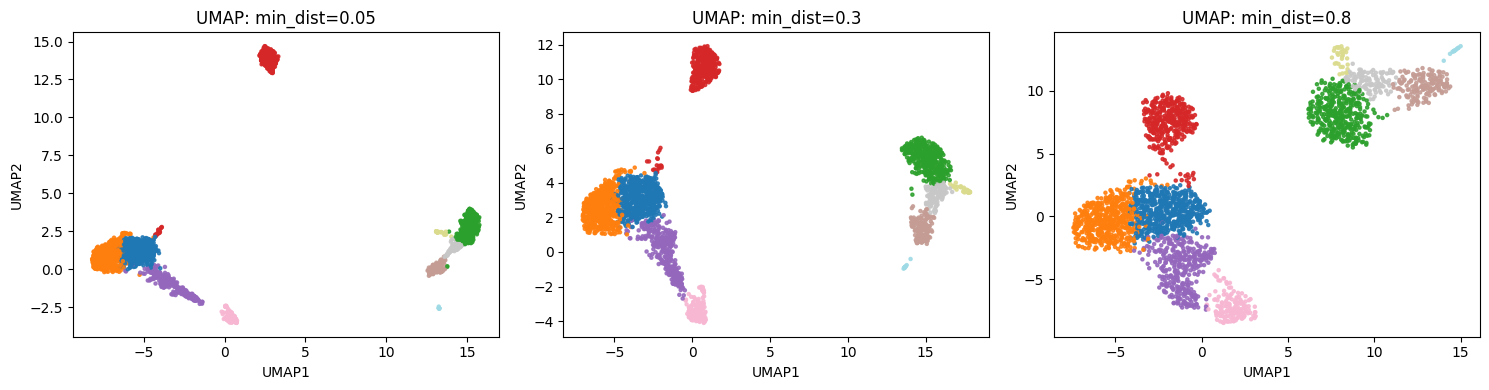

In [ ]:
from copy import deepcopy
original_umap_params = deepcopy(adata.uns.get("umap", {}))
original_embedding = adata.obsm["X_umap"].copy()
original_labels = adata.obs["leiden_1.0"].copy()

embeddings = {0.3: original_embedding}
for value in (0.05, 0.8):
    sc.tl.umap(adata, min_dist=value, random_state=42)
    embeddings[value] = adata.obsm["X_umap"].copy()

adata.obsm["X_umap"] = original_embedding  # возвращаем основной UMAP
adata.uns["umap"] = original_umap_params  # и исходные параметры в AnnData
assert original_labels.equals(adata.obs["leiden_1.0"])

labels = adata.obs["leiden_1.0"].cat.codes.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (value, xy) in zip(axes, sorted(embeddings.items())):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab20", s=5, alpha=0.85)
    ax.set(title=f"UMAP: min_dist={value}", xlabel="UMAP1", ylabel="UMAP2")
plt.tight_layout()
plt.show()

## 5.2. Проверка через биологию

Окрасим UMAP по известным генам-маркерам: `CD3D` (T-клетки), `MS4A1` (B-клетки), `NKG7` (NK-клетки), `LST1` (моноциты).

In [ ]:
markers = [g for g in ["CD3D", "MS4A1", "NKG7", "LST1"] if g in adata.var_names]

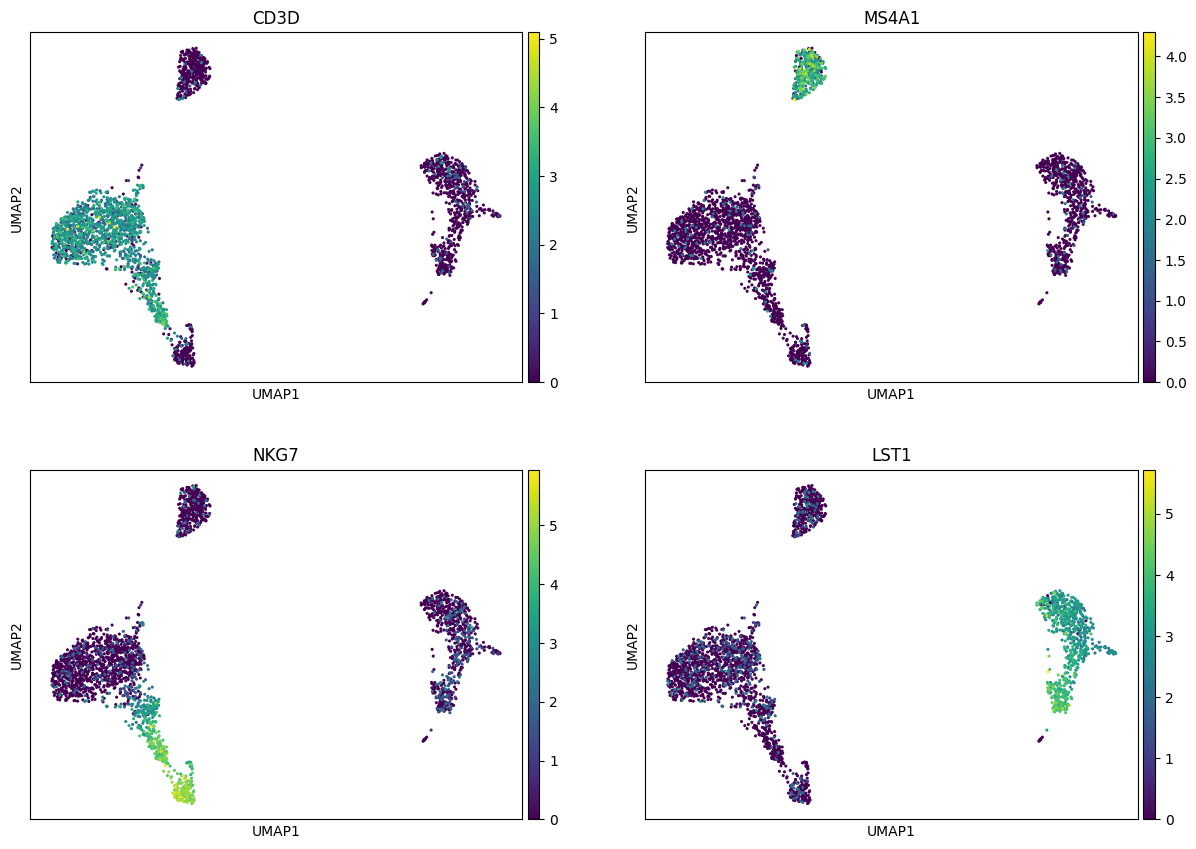

In [ ]:
sc.pl.umap(adata, color=markers, ncols=2, size=20)

## 5.3. Сохраняем результаты для следующего занятия

В `.h5ad` сохраняются исходная матрица, `X_pca`, граф соседства, все варианты меток Leiden и основная визуализация `X_umap`/`X_tsne`. На следующем семинаре можно начать с аннотации кластеров, не повторяя вычисления.

In [ ]:
result_path = Path("data/pbmc3k_after_clustering.h5ad")
adata.write_h5ad(result_path, compression="gzip")

# Самостоятельная работа: модулярность и анализ scRNA-seq

## Задание 1. Посчитать модулярность вручную

На рисунке показан **неориентированный невзвешенный граф из 9 вершин**. Рёбра внутри сообщества проведены сплошными линиями, между сообществами — пунктирными.


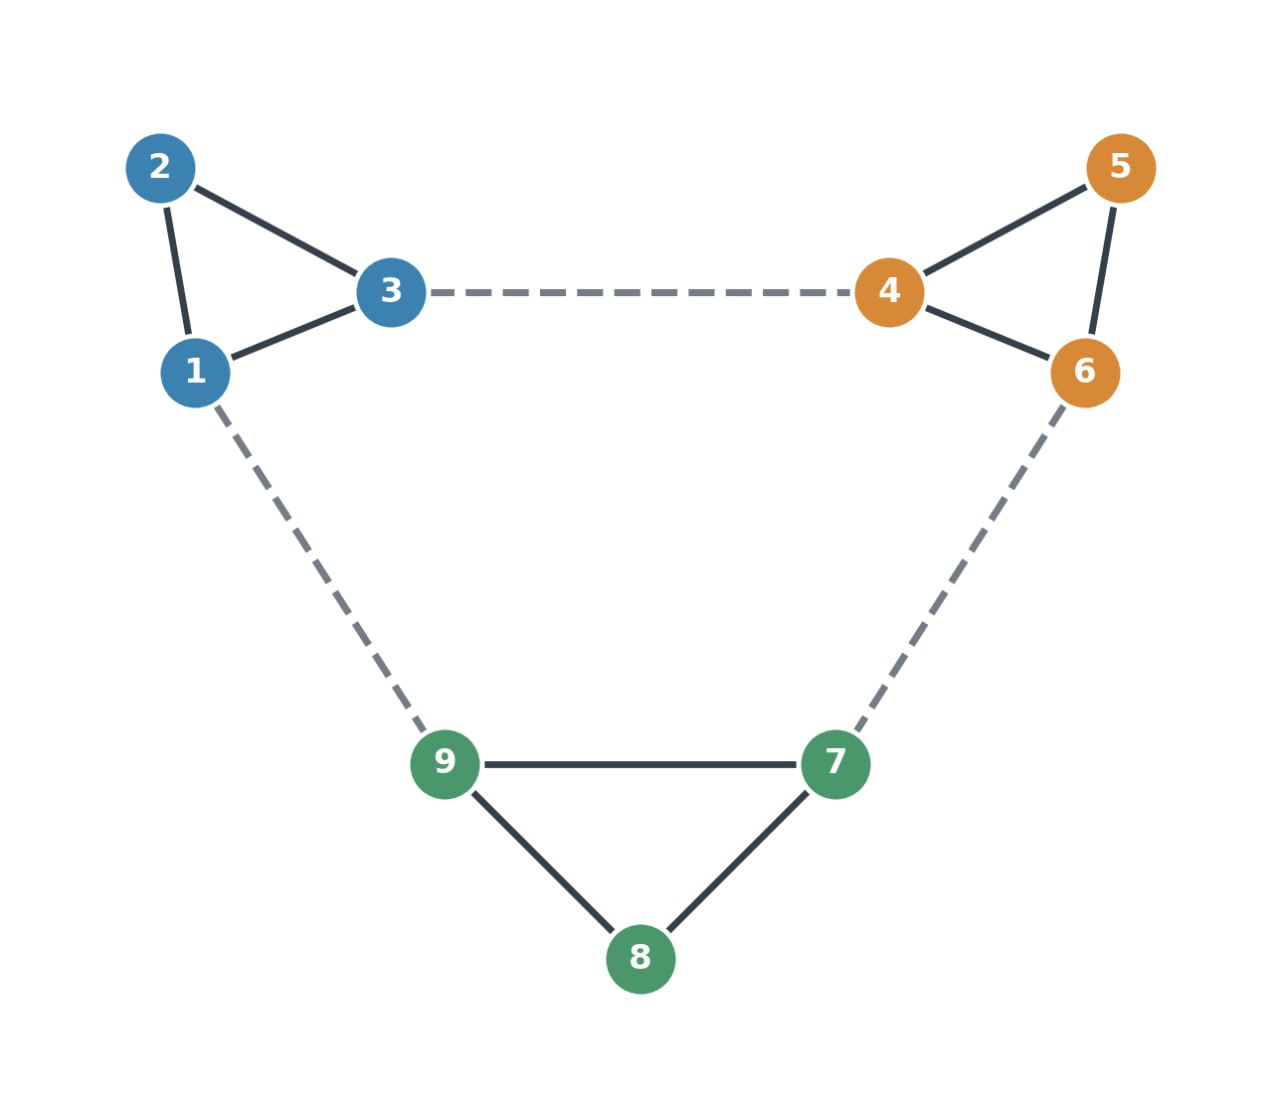

Сообщества: **A = {1, 2, 3}**, **B = {4, 5, 6}**, **C = {7, 8, 9}**.

1. Посчитайте общее число рёбер графа `m`.

    m = 12

2. Для каждого сообщества найдите `l_c` — число рёбер, оба конца которых находятся внутри сообщества, и `d_c` — сумму степеней его вершин (включая внешние связи).

    `l` = `l_a` = `l_b` = `l_c` = 3

    В каждом из сообществ у двух вершин степень = 3 и у одной = 2. Получаем сумму степеней `d` = `d_a` = `d_b` = `d_c` = 3 + 3 + 2 = 8

3. По формуле ниже вычислите **модулярность разбиения вручную**, показав промежуточные вычисления:

   $$Q=\sum_{c=1}^{3}\left(\frac{l_c}{m}-\left(\frac{d_c}{2m}\right)^2\right).$$

    Тут считается сумма вкладов каждого из трех сообществ (в нашем случае они одинаковы). Берем m = 12, l = 3, d = 8:

   $$Q = 3\left(\frac{l}{m}-\left(\frac{d}{2m}\right)^2\right)$$

   $$Q = 3\left(\frac{3}{12}-\left(\frac{8}{24}\right)^2\right) = \frac{5}{12}≈0,42$$
    
4. Объясните словами, зачем из доли внутренних рёбер вычитается второй член. Что показывает положительное значение `Q`? Является ли `Q` вероятностью?

    Второй член (d_c/2m)^2 показывает, какая доля рёбер попала бы внутрь сообщества просто случайно, если бы рёбра раздавались случайно при сохранении степеней вершин. Каждый конец ребра попадает в сообщество с вероятностью d_c/2m, а для обоих концов получается (d_c/2m)^2. Вычитать его нужно потому что сама по себе доля внутренних рёбер ничего не показывает: если объединить все вершины в одно сообщество, то l/m = 1, хотя никакой структуры нет (c вычитанием для такого разбиения Q = 1 − 1 = 0)

    Положительное Q означает, что внутри сообществ рёбер больше чем ожидалось бы при случайном соединении, те в графе есть выраженная структура групп, и чем больше Q, тем она чётче

    Q не является вероятностью. Это разность двух долей, то есть мера качества разбиения. Она может быть отрицательной (когда внутренних рёбер меньше, чем ожидалось), а её максимум меньше 1 и зависит от графа

## Задание 2. Самостоятельный анализ клеток в Scanpy

**Выберите один** набор 10x Genomics (PBMC 3k не использовать):

- [Клетки сердца эмбриона мыши E18 (~1011 клеток)](https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки головного мозга эмбриона мыши E18 (~1301 клетка)](https://www.10xgenomics.com/datasets/1-k-brain-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки селезёнки мыши (~1119 клеток)](https://www.10xgenomics.com/datasets/splenocytes-from-c-57-bl-6-mice-1-k-cells-v-2-2-standard-4-0-0)

На странице набора загрузите **Feature / cell matrix HDF5 (filtered)** (для селезёнки — матрицу **Gene Expression**, а не V(D)J). Это счётчики UMI для баркодов, уже отобранных Cell Ranger; исходные пустые капли в эту матрицу не входят.

```python
import scanpy as sc
adata = sc.read_10x_h5("путь/к/скачанному_файлу.h5")
adata.var_names_make_unique()
```

**Проведите анализ**, используя методы Scanpy, изученные на семинарах:

1. **QC.** Посчитайте и покажите распределения количества UMI (`total_counts`), обнаруженных генов (`n_genes_by_counts`) и доли митохондриальных счётчиков (`pct_counts_mt`). Выберите пороги фильтрации клеток и генов, примените их и **объясните почему выбрали именно эти значения**. Укажите, сколько клеток осталось.
2. **Нормализация и HVG.** Выполните нормализацию, `log1p` и отбор высоковариабельных генов. Укажите число HVG и объясните, зачем их отбирают и почему выбранное количество разумно.
3. **PCA.** Постройте PCA. Выберите число главных компонент для дальнейшего анализа; объясните выбор, используя график доли объяснённой дисперсии.
4. **Граф и Leiden.** Постройте граф соседей, выполните кластеризацию Leiden. Укажите `n_neighbors`, `n_pcs`, `resolution`, число получившихся кластеров и число клеток в них. Объясните выбранные параметры.
5. **UMAP и t-SNE.** Постройте обе визуализации, раскрасив точки по меткам Leiden. Также раскрасьте PCA или UMAP по одной QC-метрике и по **двум выбранным известным генам**, если они есть в данных. Опишите, что видно и какие выводы сделать нельзя.
6. **Биологический вывод.** По нескольким предложениям объясните, какие клеточные популяции **предположительно** присутствуют в выбранной ткани. Обоснуйте предположение экспрессией выбранных генов; не называйте кластеры достоверно определёнными клеточными типами.

**Разрешено:** стандартные функции Scanpy для QC, фильтрации, нормализации, HVG, PCA, графа соседей, Leiden, UMAP и t-SNE; окраска графиков по кластерам, QC-метрикам и **заданным вручную** генам.

**Не использовать:** `sc.tl.rank_genes_groups`, `sc.tl.score_genes`, методы автоматической аннотации или другие ещё не изученные методы. Подбор генов можно сделать по литературе, без автоматического поиска маркеров.

**Что сдавать:** число и расчёт модулярности; Jupyter-ноутбук с анализом одного набора данных, графиками, числом клеток до/после QC, параметрами и краткими объяснениями сделанных решений. Не требуется получить «правильное» число кластеров.


In [ ]:
import scanpy as sc
adata = sc.read_10x_h5("/content/heart_1k_v3_filtered_feature_bc_matrix.h5")
adata.var_names_make_unique()

/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


In [ ]:
adata

AnnData object with n_obs × n_vars = 1011 × 31053
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

In [ ]:
adata.var_names[adata.var_names.str.startswith("mt-")]

Index(['mt-Nd1', 'mt-Nd2', 'mt-Co1', 'mt-Co2', 'mt-Atp8', 'mt-Atp6', 'mt-Co3',
       'mt-Nd3', 'mt-Nd4l', 'mt-Nd4', 'mt-Nd5', 'mt-Nd6', 'mt-Cytb'],
      dtype='str')

##1) QC

In [ ]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

print("Клеток до QC:", adata.n_obs, "| генов:", adata.n_vars)
adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1)

Клеток до QC: 1011 | генов: 31053


,total_counts,n_genes_by_counts,pct_counts_mt
count,1011.0,1011.0,1011.0
mean,13986.7,2620.7,14.3
std,15786.7,2152.6,17.3
min,506.0,17.0,0.0
1%,609.1,35.0,0.0
5%,789.0,63.5,0.0
25%,2846.0,644.5,4.6
50%,7610.0,2058.0,7.2
75%,19775.0,4370.0,20.0
95%,46641.0,6357.0,50.5


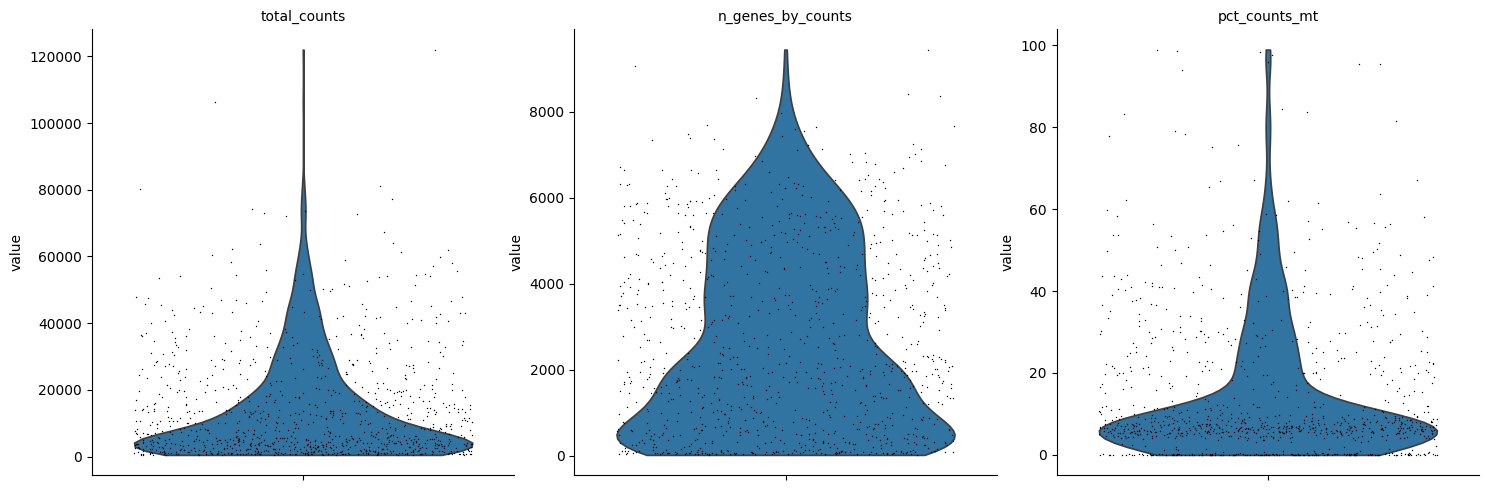

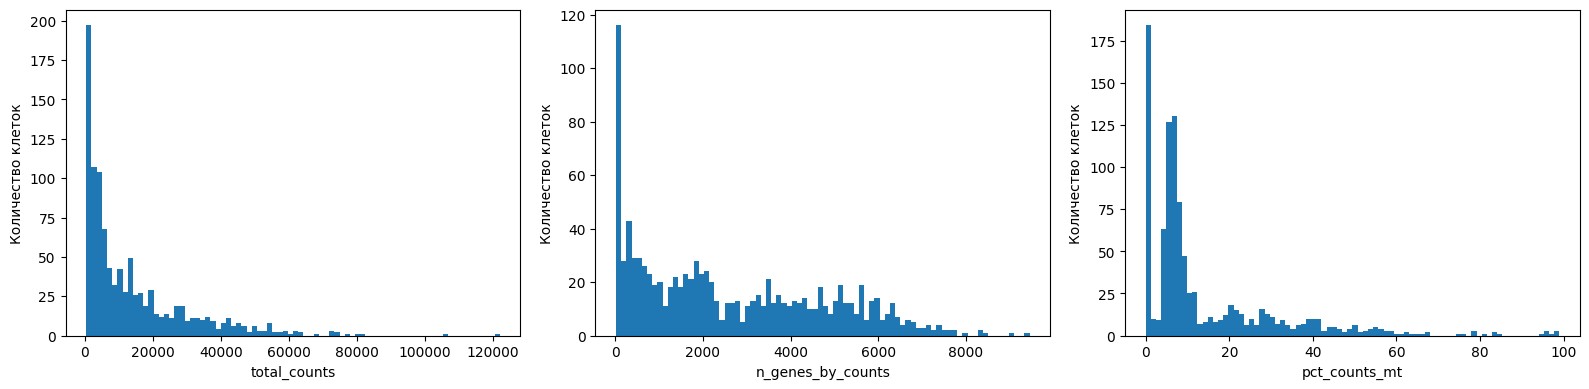

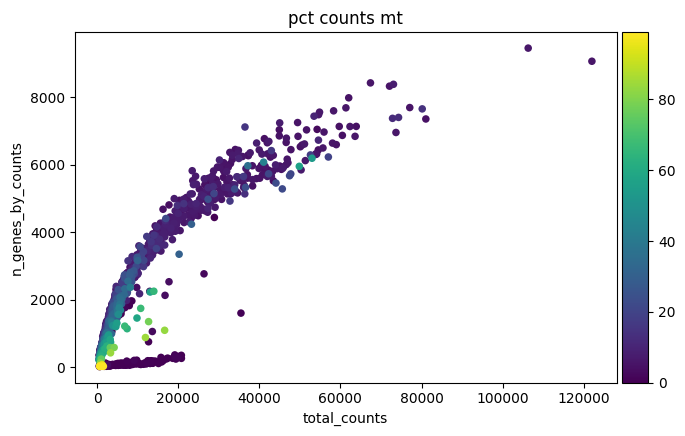

In [ ]:
metrics = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]

sc.pl.violin(adata, metrics, jitter=0.4, multi_panel=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(axes, metrics):
    ax.hist(adata.obs[m], bins=80)
    ax.set_xlabel(m)
    ax.set_ylabel("Количество клеток")
plt.tight_layout()
plt.show()

sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

Посмотрим на группу клеток внизу scatter. У этих клеток много UMI, но очень мало генов и почти нет митохондриальных UMI. Им соответствуют пик около нуля на гистограмме генов (около 115 клеток) и пик около 0% на гистограмме митохондриальных UMI. Скорее всего это эритроциты (в эмбриональном сердце много крови и у эритроцитов нет ядра и митохондрий, почти вся их РНК - гемоглобин). Проверим: отметим гены гемоглобина, посчитаем для каждой клетки долю UMI гемоглобина и раскрасим по ней тот же график

['Hbb-bt', 'Hbb-bs', 'Hbb-bh2', 'Hbb-bh1', 'Hbb-y', 'Hba-x', 'Hba-a1', 'Hba-a2']


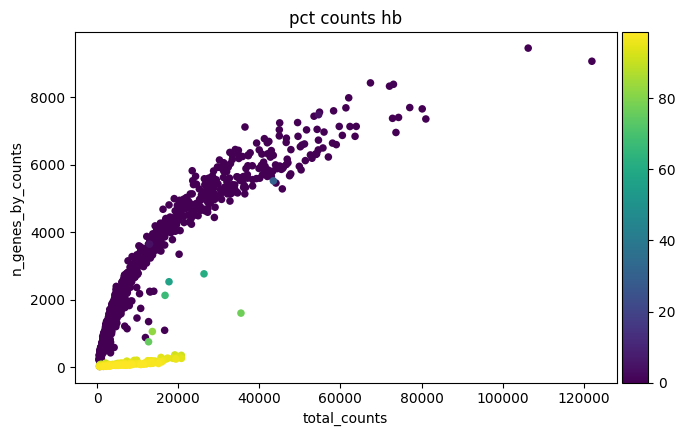

In [ ]:
adata.var["hb"] = adata.var_names.str.match(r"^Hb[ab]-")
print(list(adata.var_names[adata.var["hb"]]))
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "hb"], percent_top=None, log1p=False, inplace=True)
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_hb")

У клеток этой группы 90–100% UMI приходится на гемоглобин, а у остальных клеток доля гемоглобина близка к нулю, значит это эритроциты. Поэтому при фильтрации мы добавим порог по доле гемоглобина

In [ ]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[(adata.obs["n_genes_by_counts"] <= 8000)
              & (adata.obs["pct_counts_mt"] <= 40)
              & (adata.obs["pct_counts_hb"] <= 20)].copy()
print("Клеток после QC:", adata.n_obs, "| генов:", adata.n_vars)

Клеток после QC: 768 | генов: 16619


До фильтрации в данных 1011 клеток и 31 053 гена. Медиана числа UMI на клетку — 7610, медиана числа обнаруженных генов - 2058, медиана доли митохондриальных UMI - 7,2%

Выбранные пороги:

не менее 200 генов - удаляет пустые капли и фрагменты клеток

не более 8000 генов (около 99го перцентиля) - удаляет вероятные дублеты

не более 40% митохондриальных UMI - удаляет повреждённые клетки с долей 60–99% и малым числом генов (порог выше стандартных 5%, потому что в сердце у части нормальных клеток доля митохондриальных UMI составляет 15–40% - это кардиомиоциты, в которых много митохондрий)

не более 20% UMI гемоглобина - удаляет эритроциты и их дублеты

также гены, обнаруженные менее чем в 3 клетках, удалены

После фильтрации осталось 768 клеток и 16619 генов

##2) Нормализация и HVG

Методом seurat_v3 на сырых counts отберем 2000 высоковариабельных генов из 16 619 генов, оставшихся после QC (около 12%)

Высоковариабельные гены - это гены, экспрессия которых различается между клетками сильнее, чем ожидается при их среднем уровне. Именно по ним отличаются типы клеток, а большинство остальных генов экспрессируются примерно одинаково и добавляют в анализ в основном шум. Поэтому PCA и дальнейший анализ строят только по HVG (так разделение клеток становится чётче и вычисления быстрее). 2000 генов достаточно, чтобы захватить маркеры всех основных типов клеток, и при этом в список почти не попадают шумные гены с низкой экспрессией

Число HVG: 2000


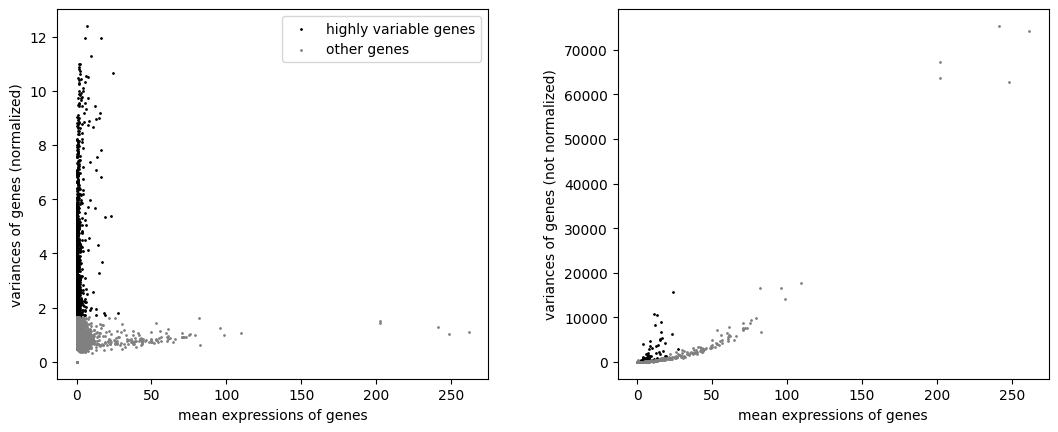

In [ ]:
adata.layers["counts"] = adata.X.copy()

sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
print("Число HVG:", adata.var["highly_variable"].sum())
sc.pl.highly_variable_genes(adata)

На графике видно, что HVG не самые сильно экспрессируемые гены. Гены с наибольшим средним уровнем экспрессии в список не вошли, тк их дисперсия соответствует ожидаемой при таком среднем

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 768 × 16619
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_hb', 'pct_counts_hb', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'hb', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: None (.X), 'counts'

In [ ]:
hvg = adata.var[adata.var["highly_variable"]].sort_values("highly_variable_rank")
print(hvg.index[:30])

Index(['Ttn', 'Myh7', 'Myl2', 'Myl3', 'Krt19', 'Mb', 'Msln', 'Mybpc3',
       'Prss16', 'Actc1', 'Rarres2', 'Myh6', 'Krt18', 'Pax1', 'H2-Ab1',
       'Krt17', 'Krt8', 'Igfbp6', 'Pltp', 'Acta2', 'Fabp4', 'Upk3b', 'Pln',
       'Actn2', 'H2-Aa', 'Cox6a2', 'Ankrd1', 'Plvap', 'Cd74', 'Tbata'],
      dtype='str')


Среди самых вариабельных генов есть маркеры разных типов клеток сердца. Интересно, что встретились гены эпителия тимуса (Prss16, Pax1) - вероятно при выделении сердца в образец попала какая-то часть. Это подтверждает что HVG отражают различия между типами клеток

##3) PCA

Построим PCA  по 2000 HVG + рассчитаем 50 главных компонент

In [ ]:
sc.tl.pca(adata, mask_var="highly_variable", n_comps=50) #PCA по HGV

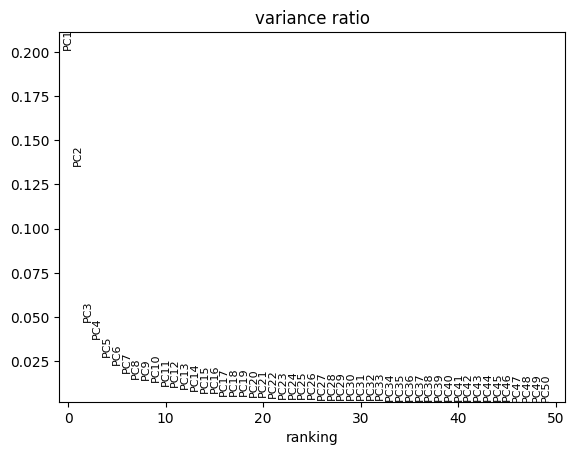

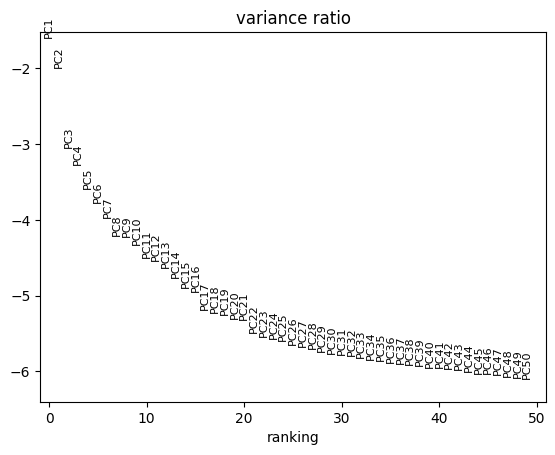

In [ ]:
#доля объяснённой дисперсии
sc.pl.pca_variance_ratio(adata, n_pcs=50)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True) #логарифмическая шкала

In [ ]:
vr = adata.uns["pca"]["variance_ratio"]
for i in range(30):
    print(f"PC{i+1}: {vr[i]*100:.2f}%   накопленная: {vr[:i+1].sum()*100:.1f}%")

PC1: 20.11%   накопленная: 20.1%
PC2: 13.57%   накопленная: 33.7%
PC3: 4.74%   накопленная: 38.4%
PC4: 3.78%   накопленная: 42.2%
PC5: 2.75%   накопленная: 45.0%
PC6: 2.29%   накопленная: 47.2%
PC7: 1.87%   накопленная: 49.1%
PC8: 1.49%   накопленная: 50.6%
PC9: 1.47%   накопленная: 52.1%
PC10: 1.32%   накопленная: 53.4%
PC11: 1.11%   накопленная: 54.5%
PC12: 1.07%   накопленная: 55.6%
PC13: 0.97%   накопленная: 56.6%
PC14: 0.86%   накопленная: 57.4%
PC15: 0.74%   накопленная: 58.2%
PC16: 0.71%   накопленная: 58.9%
PC17: 0.56%   накопленная: 59.4%
PC18: 0.54%   накопленная: 60.0%
PC19: 0.53%   накопленная: 60.5%
PC20: 0.50%   накопленная: 61.0%
PC21: 0.49%   накопленная: 61.5%
PC22: 0.41%   накопленная: 61.9%
PC23: 0.39%   накопленная: 62.3%
PC24: 0.38%   накопленная: 62.7%
PC25: 0.37%   накопленная: 63.0%
PC26: 0.35%   накопленная: 63.4%
PC27: 0.34%   накопленная: 63.7%
PC28: 0.34%   накопленная: 64.1%
PC29: 0.32%   накопленная: 64.4%
PC30: 0.31%   накопленная: 64.7%


На графике первые две компоненты объясняют заметно больше остальных, после чего доля резко падает. Компоненты после ~20й объясняют примерно одинаково малую долю дисперсии и отражают в основном шум

Для дальнейшего анализа выберем 20 главных компонент. Резкий локоть на линейном графике приходится на ~5ю компоненту, но ограничиваться только ей может быть рискованно (компоненты 6–20 ещё несут сигнал, который может отражать менее многочисленные популяции клеток)

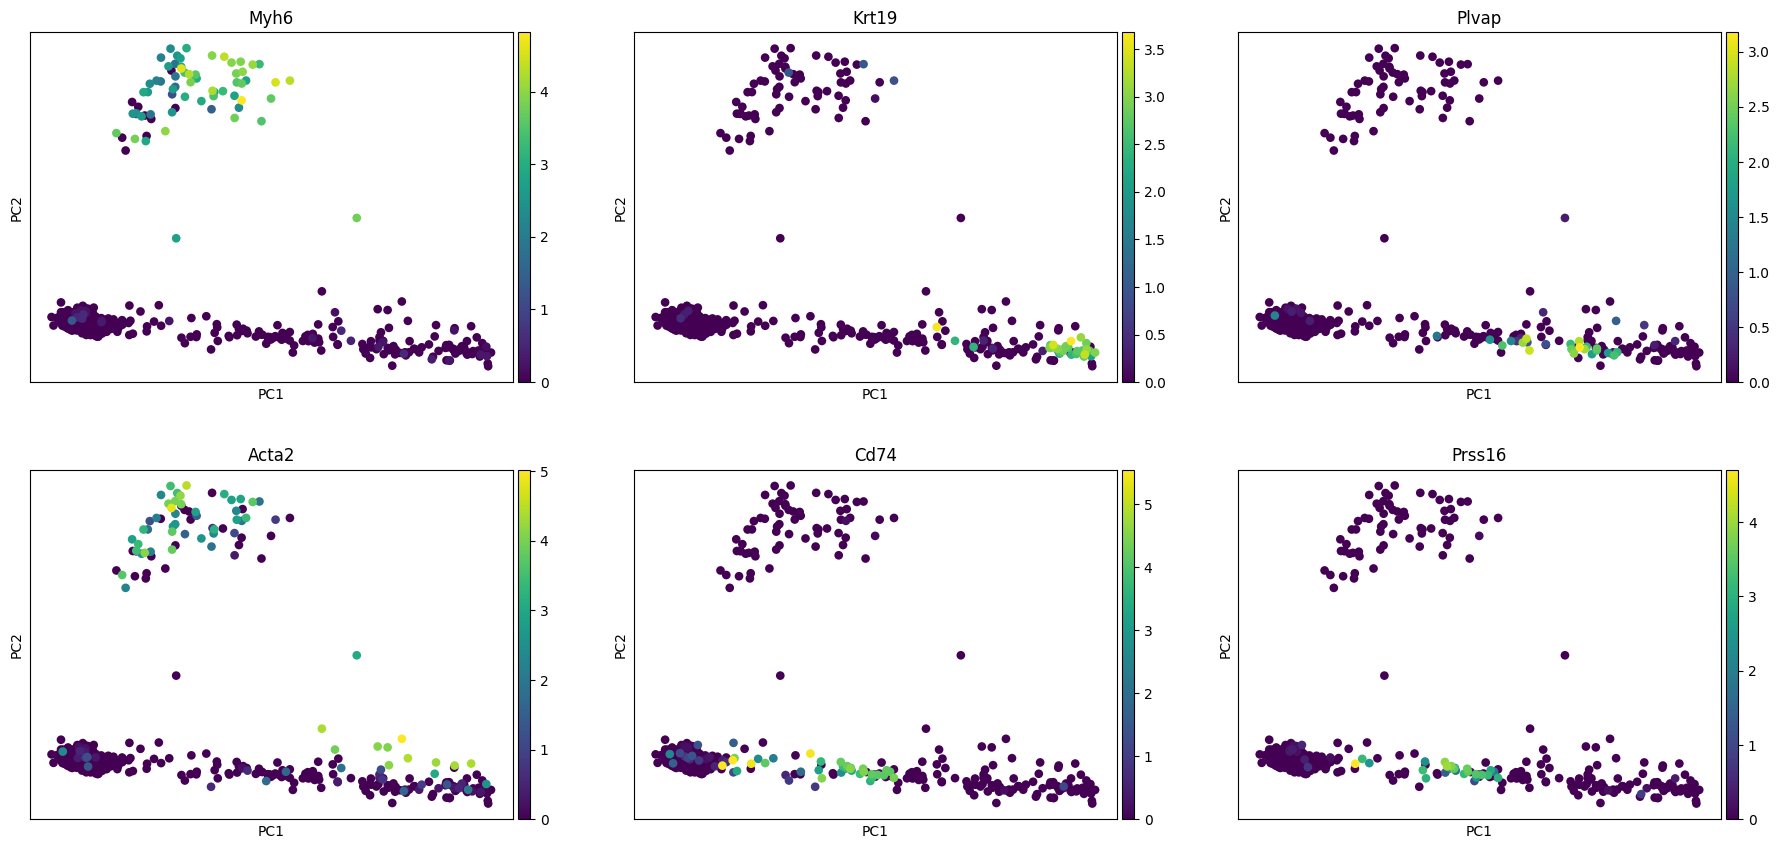

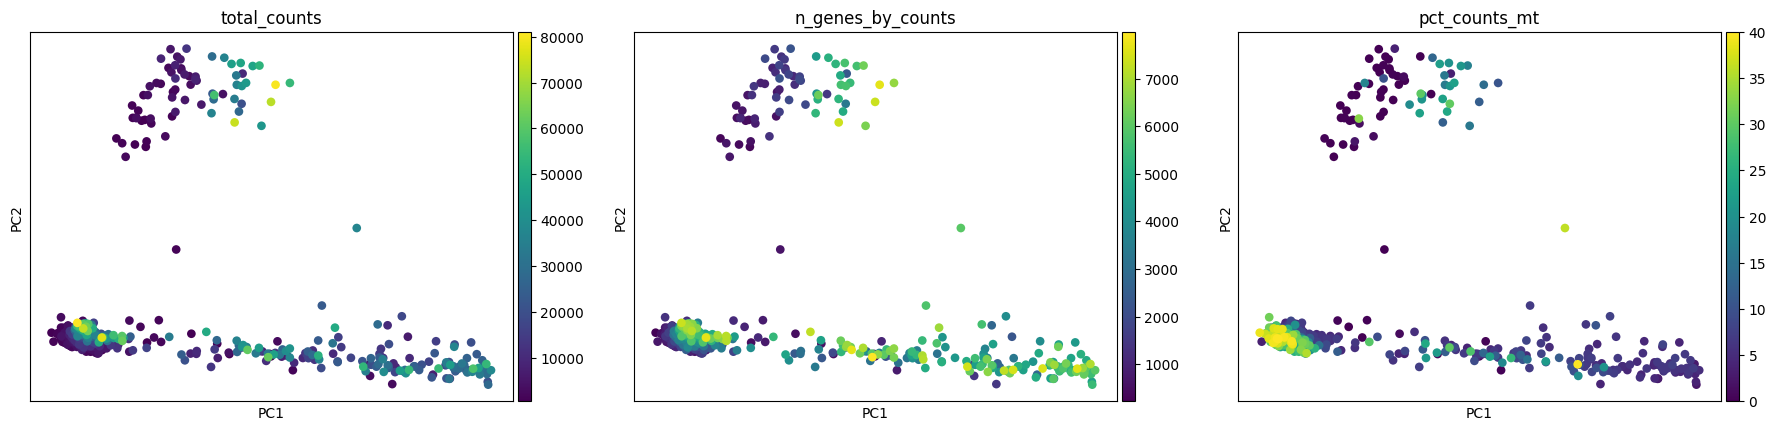

In [ ]:
sc.pl.pca(adata, color=["Myh6", "Krt19", "Plvap", "Acta2", "Cd74", "Prss16"], ncols=3)
sc.pl.pca(adata, color=["total_counts", "n_genes_by_counts", "pct_counts_mt"])

На PCA окрашенной по маркерам видно, что первые компоненты отражают биологические различия между типами клеток. PC2 отделяет кардиомиоциты (Myh6) от остальных клеток. Вдоль PC1 нижняя группа клеток расходится - с одного края находятся клетки эпикарда (Krt19) и эндотелия (Plvap), с другого клетки с маркерами антигенпрезентирующих клеток (Cd74) и тимуса (Prss16)

##4) Граф и Leiden

Возьмем параметры

n_neighbors=15 - стандартное значение, которое при 768 клетках даёт локальный граф (меньшее число соседей сделало бы граф шумным и неустойчивым, а большее связывало бы клетки разных типов, и небольшие популяции могли бы раствориться в крупных)

n_pcs=20 выбрано по графику доли объяснённой дисперсии на предыдущем шаге

In [ ]:
from scipy.sparse.csgraph import connected_components
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20, metric="euclidean", method="umap", random_state=42)

G = adata.obsp["connectivities"].tocsr()
degree = np.asarray((G > 0).sum(axis=1)).ravel()
n_comp, _ = connected_components(G, directed=False)
print("Число компонент связности:", n_comp)
print("Минимум / медиана / максимум степеней:", degree.min(), np.median(degree), degree.max())

Число компонент связности: 1
Минимум / медиана / максимум степеней: 14 17.0 45


 Значение `resolution` выберем, сравнив несколько вариантов

/tmp/ipykernel_3246/3710890098.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}", random_state=42)
/tmp/ipykernel_3246/3710890098.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=r

resolution=0.1: кластеров 8
resolution=0.2: кластеров 11


/tmp/ipykernel_3246/3710890098.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}", random_state=42)
/tmp/ipykernel_3246/3710890098.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=r

resolution=0.5: кластеров 13
resolution=1.0: кластеров 14


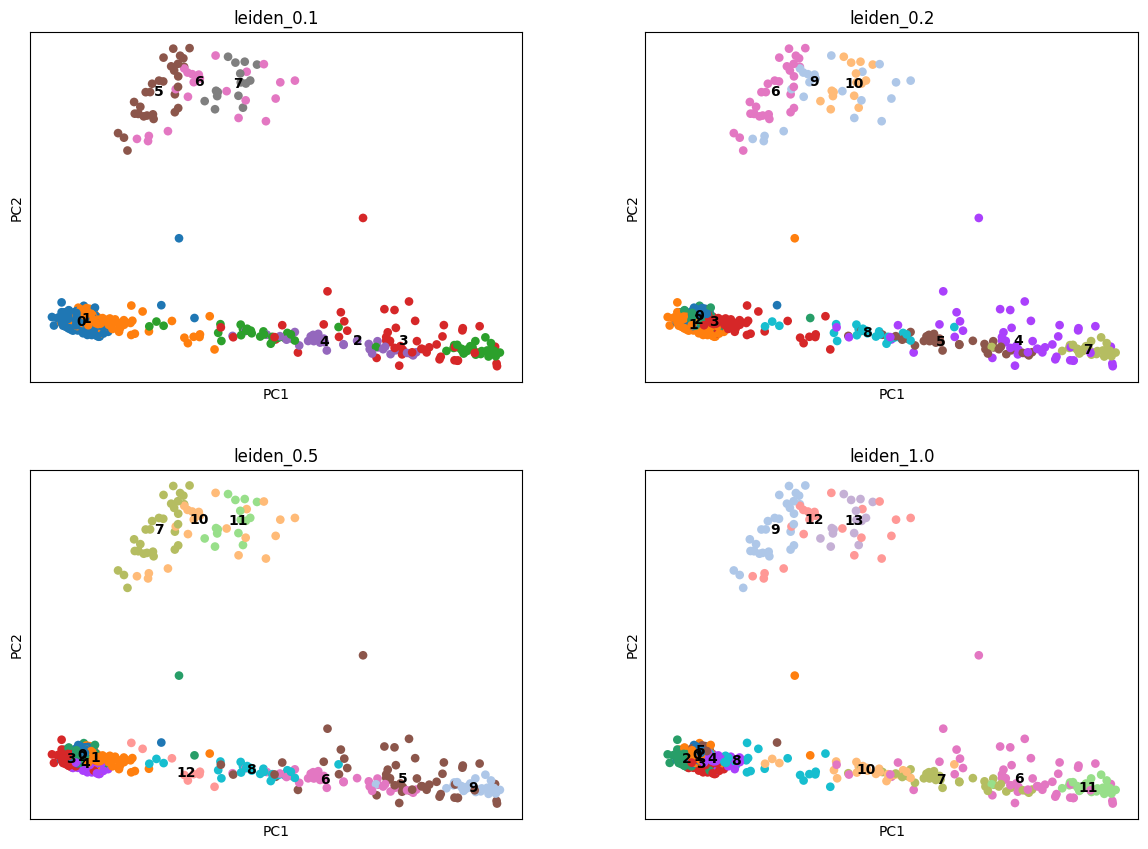

In [ ]:
for res in [0.1, 0.2, 0.5, 1.0]:
    sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}", random_state=42)
    print(f"resolution={res}: кластеров {adata.obs[f'leiden_{res}'].nunique()}")

sc.pl.pca(adata, color=["leiden_0.1", "leiden_0.2", "leiden_0.5", "leiden_1.0"], ncols=2, legend_loc="on data")

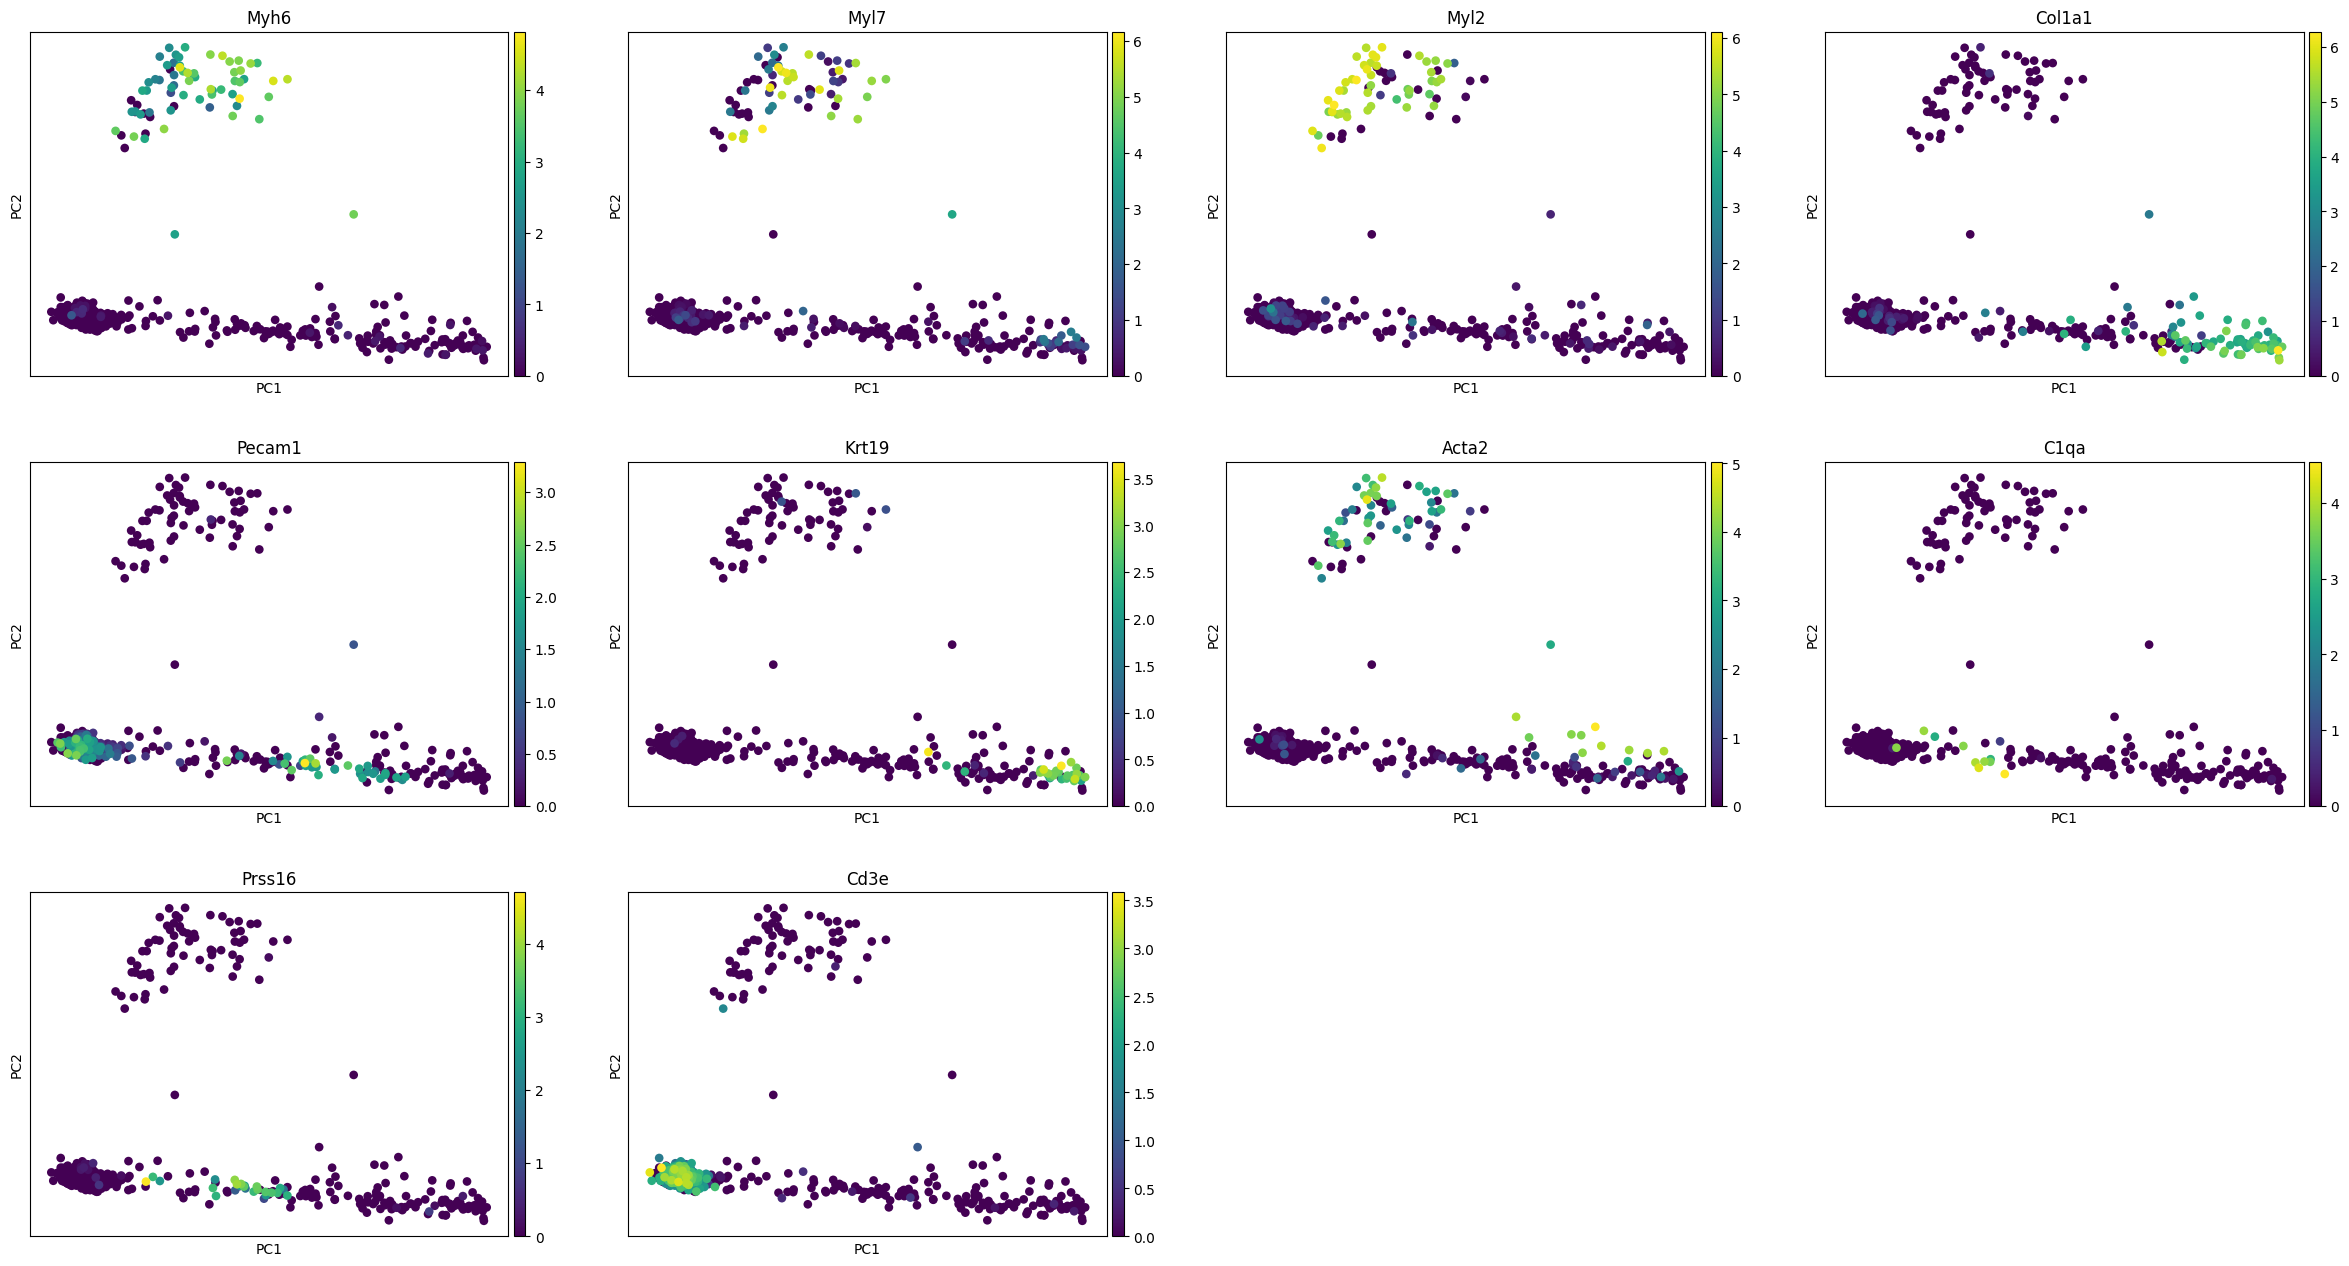

In [ ]:
markers = ["Myh6", "Myl7", "Myl2", "Col1a1", "Pecam1", "Krt19", "Acta2", "C1qa", "Prss16", "Cd3e"]
markers = [g for g in markers if g in adata.var_names]

sc.pl.pca(adata, color=markers, ncols=4)

Leiden разбивает клетки по структуре графа и не учитывает биологию, поэтому для выбора разрешения клетки окрашены по известным маркерам типов клеток: кардиомиоциты (Myh6, Myl7, Myl2), T-клетки тимуса (Cd3e), эпителий тимуса (Prss16), эндотелий (Pecam1), фибробласты (Col1a1), эпикард (Krt19), гладкомышечные клетки (Acta2), макрофаги (C1qa). Хорошее разбиение - то, при котором область экспрессии каждого маркера совпадает с отдельным кластером

Выберем resolution = 0.2 (11 кластеров) - при нём разные типы клеток оказываются в разных кластерах. При 0.1 эпителий тимуса объединяется в один кластер с эпикардом и фибробластами, а при 0.5 и 1.0 те же популяции лишь сильнее дробятся без появления новых типов клеток

leiden_0.2
0     192
1     153
2     115
3      97
4      53
5      35
6      31
7      27
8      27
9      23
10     15
Name: count, dtype: int64


<Axes: xlabel='Кластер', ylabel='Число клеток'>

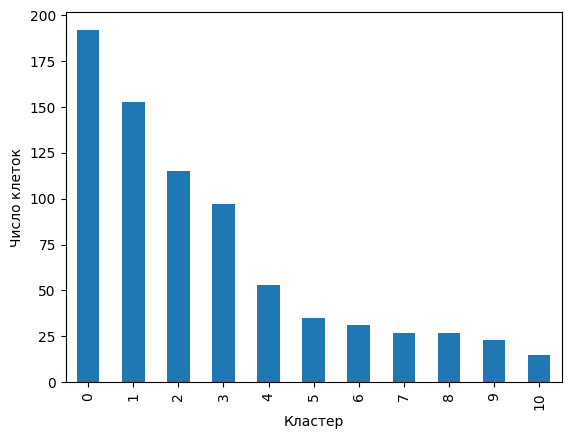

In [ ]:
print(adata.obs["leiden_0.2"].value_counts().sort_index())
adata.obs["leiden_0.2"].value_counts().sort_index().plot.bar(xlabel="Кластер", ylabel="Число клеток")

Число клеток в кластерах приведено в ячейке выше. Кластеры сильно различаются по размеру: от 15 до 192 клеток. Самые крупные кластеры расположены в области высокой экспрессии маркера T-клеток Cd3e. Поскольку в сердце эмбриона T-клеток мало, а среди HVG и на PCA выявлены маркеры эпителия тимуса (Prss16, Pax1), вероятно, при выделении сердца в образец попала часть прилегающего тимуса, и эти кластеры представляют T-клетки тимуса. Кардиомиоциты (Myh6) разделены на три небольших кластера (6, 9, 10), остальные популяции представлены кластерами по 15–50 клеток

##5) UMAP и t-SNE

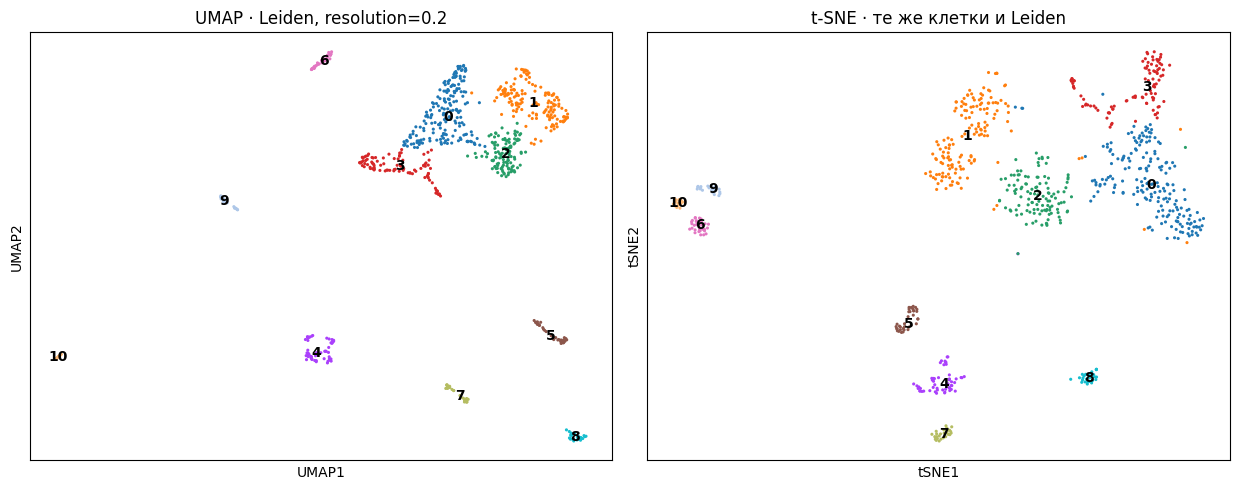

In [ ]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)
sc.tl.tsne(adata, use_rep="X_pca", n_pcs=20, perplexity=30, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
sc.pl.umap(adata, color="leiden_0.2", legend_loc="on data",
           title="UMAP · Leiden, resolution=0.2", ax=axes[0], show=False, size=20)
sc.pl.tsne(adata, color="leiden_0.2", legend_loc="on data",
           title="t-SNE · те же клетки и Leiden", ax=axes[1], show=False, size=20)
plt.tight_layout()
plt.show()

UMAP построен по графу, полученному в предыдущем пункте (min_dist = 0.3), t-SNE по первым 20 главным компонентам (perplexity = 30). Дополнительно раскрасим UMAP по одной QC-метрике и двум выбранным генам:

доля митохондриальных UMI (pct_counts_mt) - в сердце она особенно информативна, тк у кардиомиоцитов, богатых митохондриями, ожидается повышенная доля митохондриальных UMI

Myh6 - маркер кардиомиоцитов (основного типа клеток сердца)

Cd3e - маркер T-клеток, по нему проверим предположение из пункта 4 (о том что крупнейшие кластеры представляют T-клетки тимуса)

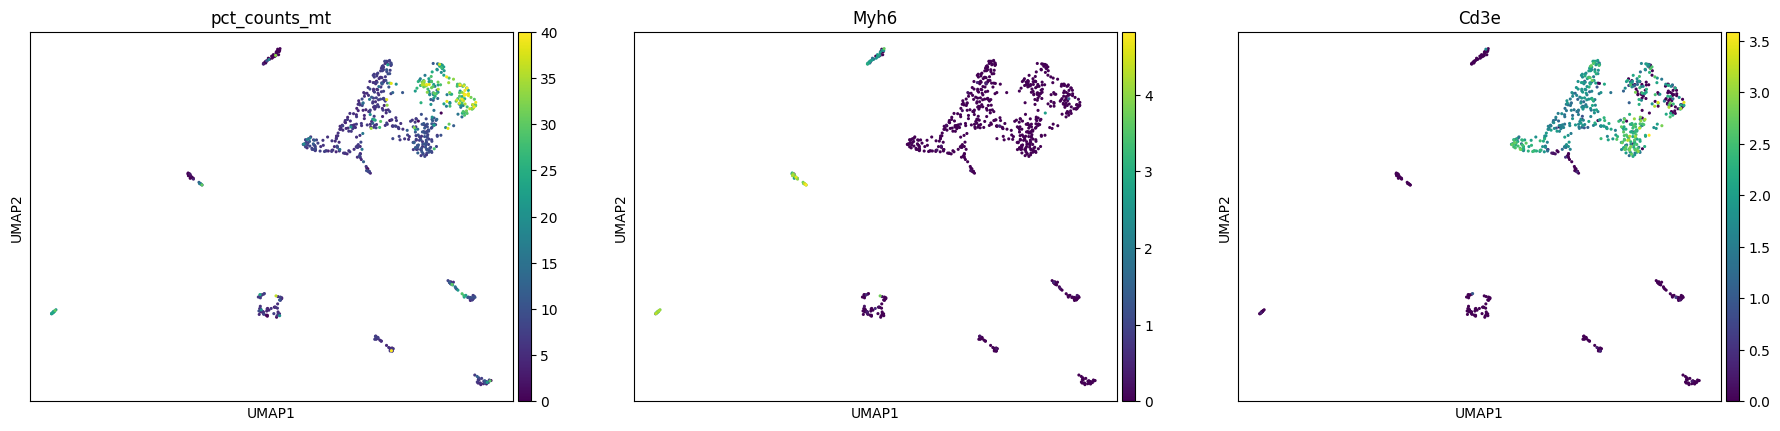

In [ ]:
#UMAP окрашенный по qc и двум генам
sc.pl.umap(adata, color=["pct_counts_mt", "Myh6", "Cd3e"], ncols=3, size=20)

Что мы видим:

* Кластеры 0-3 на обеих картинках образуют одну большую связную область, а кластеры 4-10 отдельные небольшие группы

* Cd3e экспрессируется в основном в кластерах 0–3, а Myh6 в кластерах 6,9 и 10. Это согласуется с предположением о том что кластеры 0–3 - T-клетки, а кластеры 6,9 и 10 - кардиомиоциты. Это гипотеза, опирающаяся на один маркер на каждый тип, а не установленная клеточная идентичность

* Доля митохондриальных UMI распределена неоднородно. Самые высокие значения наблюдаются у части клеток кластера 1, который при этом Cd3e-положительный. Для лимфоцитов такая доля нетипична, поэтому кластер 1 может частично отражать технический фактор (мб повреждённые клетки прошедшие порог 40%). Среди кластеров кардиомиоцитов повышенная доля заметна только в кластере 10, в кластере 6 она низкая. Наше ожидание по поводу высокого содержания mt_UMI в кардиомиоцитах подтвердилось лишь частично

Какие выводы сделать нельзя:

* Нельзя судить по расстояниям между группами. Кластеры Myh6 в UMAP далеко друг от друга, а в t-SNE рядом, поэтому взаимное расположение групп на картах не интерпретируется
* Нельзя судить по размеру, плотности и форме групп. Малые кластеры (9 и 10) в UMAP растянуты, а площадь на карте не равна числу клеток
* Нельзя считать каждый кластер отдельным типом клеток. Leiden зависит от resolution (например у нас кардиомиоциты при 0,2 уже разбиты на три кластера и мы не показали, что это разные популяции)
* Нельзя определять тип по одному гену (отсутствие сигнала тоже не доказывает отсутствие экспрессии)
* Нельзя трактовать высокую долю mt однозначно: она может отражать либо биологию, либо плохое качество клеток
* Вид UMAP и t-SNE зависит от параметров (`min_dist`, `perplexity`) и random_state

##6) Биологический вывод

Чтобы предположить, какие клеточные популяции присутствуют в образце, я раскрасила UMAP по экспрессии генов-маркеров, выбранных вручную

Проверялись маркеры кардиомиоцитов (Myh6, Tnnt2, Myl7, Myl2), T-клеток и тимоцитов (Cd3e, Cd4, Cd8a, Rag1), эпителия тимуса (Prss16, Pax1, Epcam), антиген-презентирующих клеток и макрофагов (Cd74, H2-Ab1, C1qa), эпикарда (Krt19, Msln, Upk3b), эндотелия (Plvap, Cdh5) и фибробластов (Col1a1, Dcn). Гены, отсутствующие в данных после QC, пропускались.

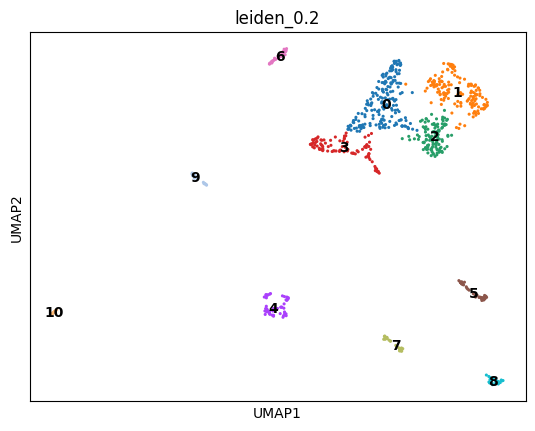

кардиомиоциты


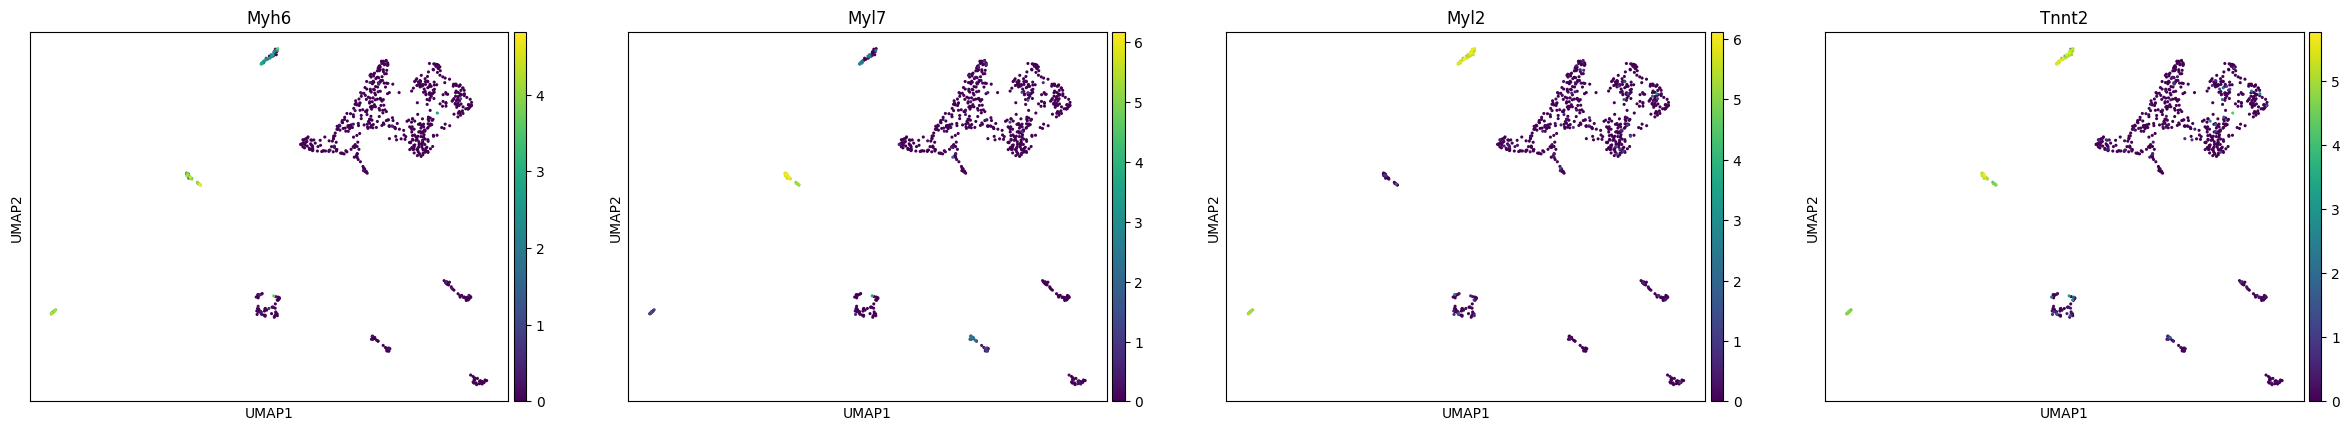

T-клетки/тимоциты


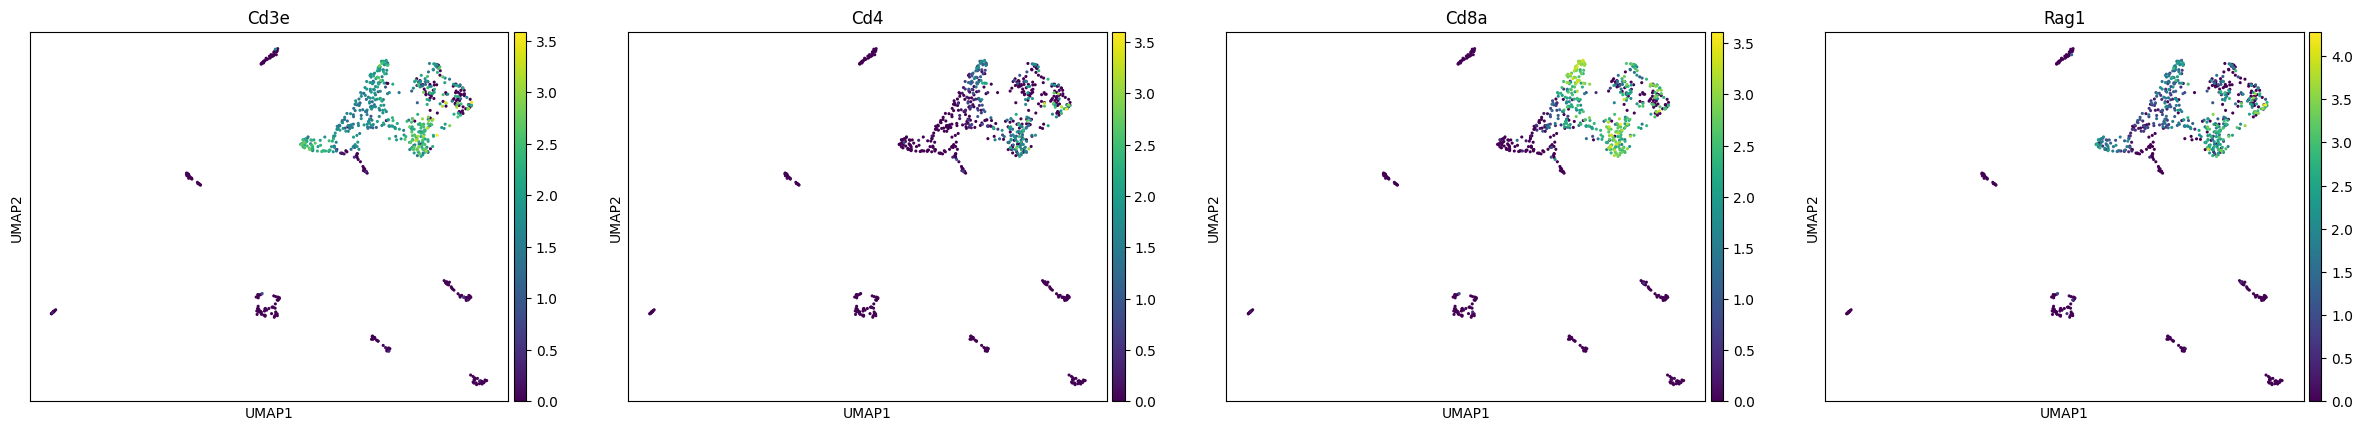

эпителий тимуса


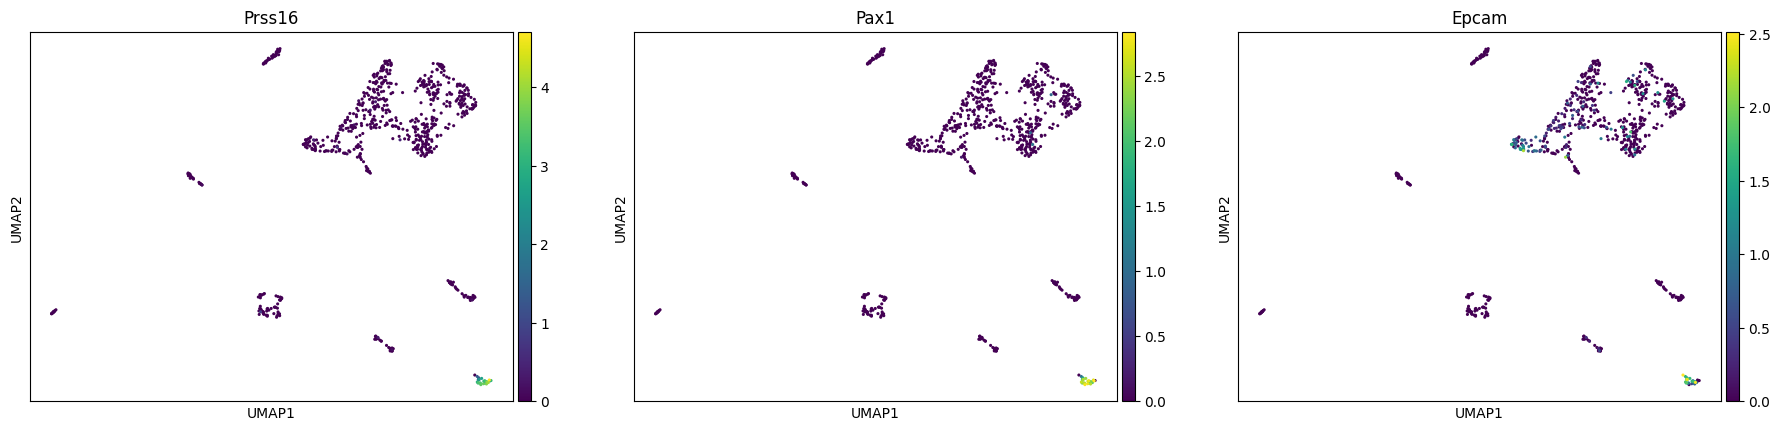

APC/макрофаги


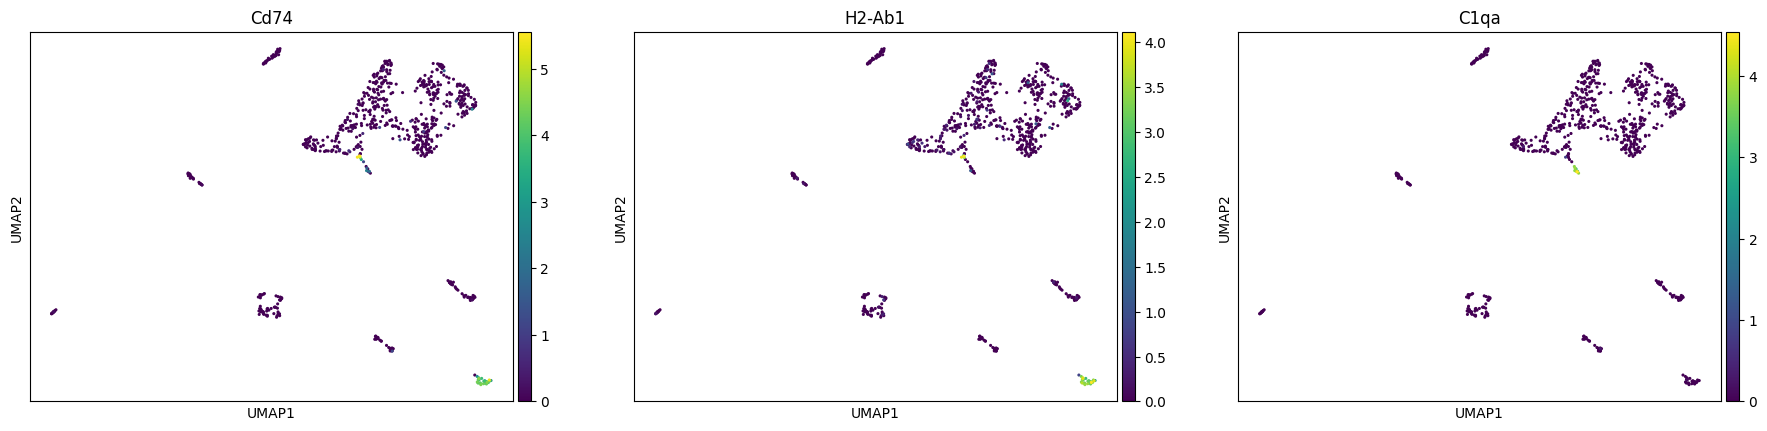

эпикард/мезотелий


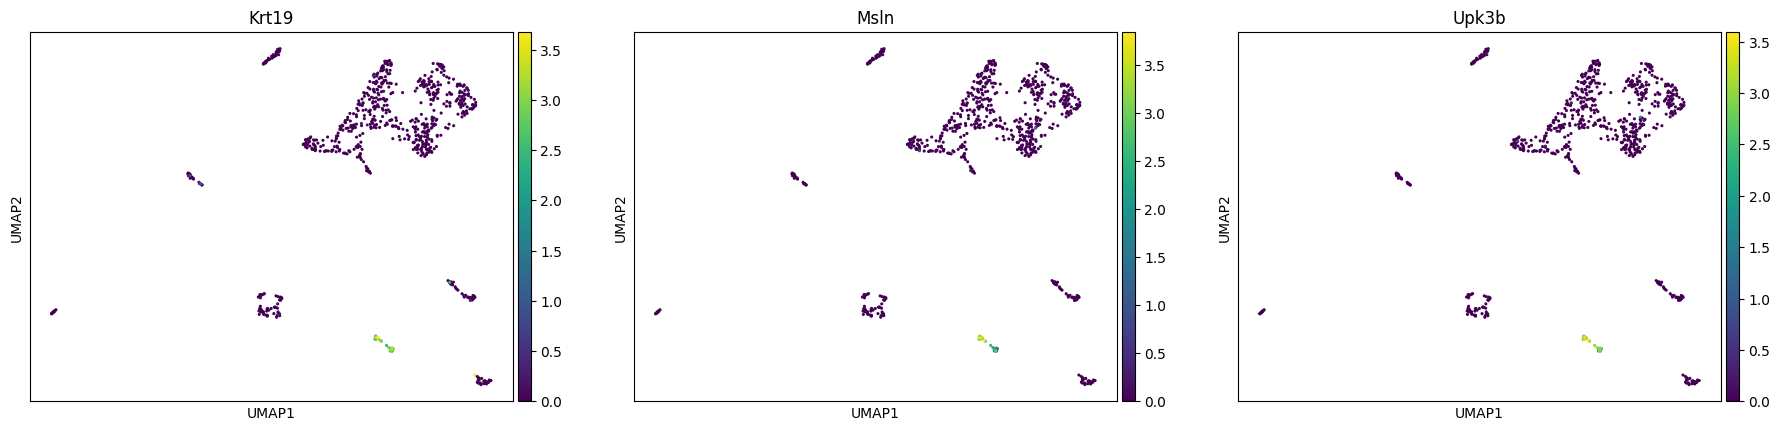

эндотелий


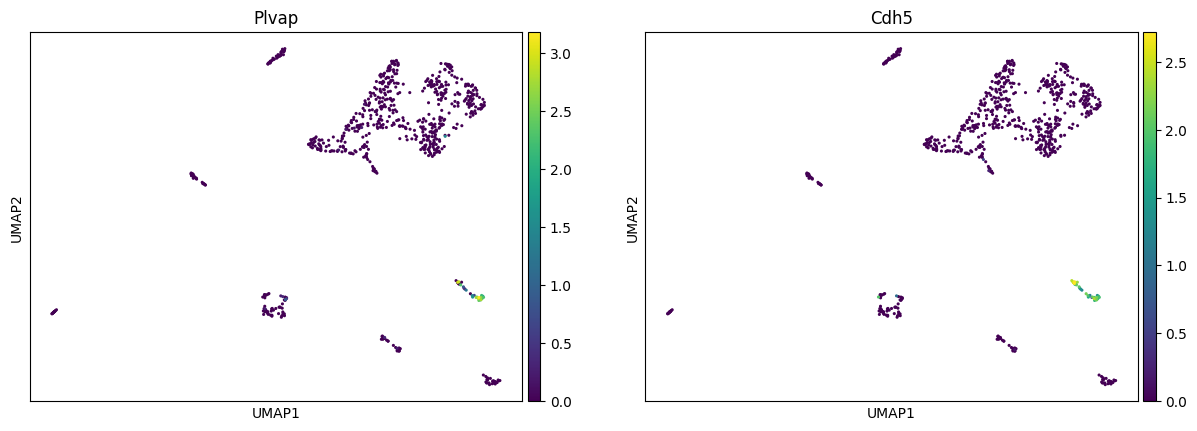

фибробласты


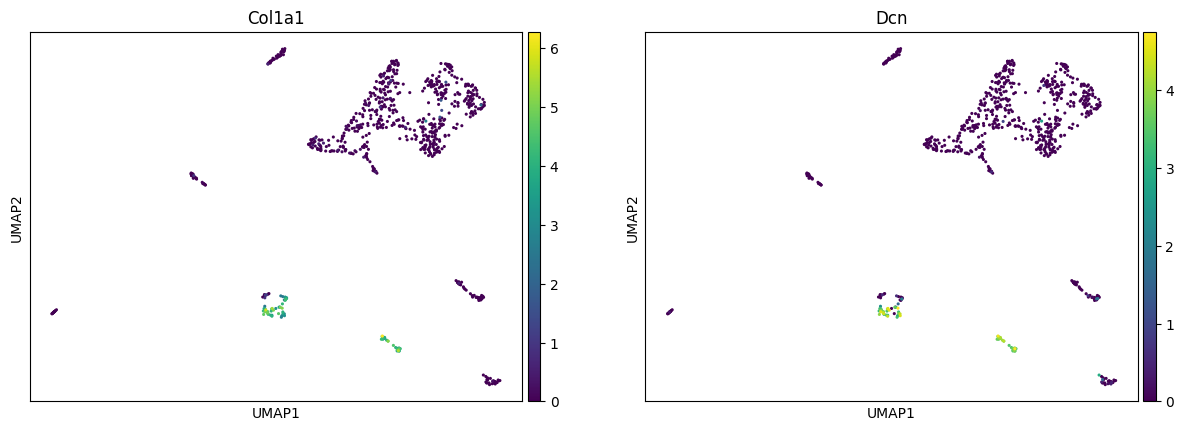

In [ ]:
sc.pl.umap(adata, color="leiden_0.2", legend_loc="on data", size=20)
candidate_markers = {
    "кардиомиоциты":        ["Myh6", "Myl7", "Myl2", "Tnnt2"],
    "T-клетки/тимоциты":    ["Cd3e", "Cd4", "Cd8a", "Rag1"],
    "эпителий тимуса":      ["Prss16", "Pax1", "Epcam"],
    "APC/макрофаги":        ["Cd74", "H2-Ab1", "C1qa"],
    "эпикард/мезотелий":    ["Krt19", "Msln", "Upk3b"],
    "эндотелий":            ["Plvap", "Cdh5"],
    "фибробласты":          ["Col1a1", "Dcn"]}

for name, genes in candidate_markers.items():
    genes = [g for g in genes if g in adata.var_names]
    if genes:
        print(name)
        sc.pl.umap(adata, color=genes, ncols=4, size=20)

По экспрессии выбранных мной генов-маркеров в образце предположительно присутствуют следующие популяции:
* Кластеры 0–3 (557 из 768 клеток, около 72%) предположительно представляют Т-лимфоциты, вероятно, незрелые тимоциты (экспрессируются Cd3e, Cd4, Cd8a и Rag1). Поскольку для сердца такая доля лимфоцитов необычна, а среди высоковариабельных генов оказались Prss16 и Pax1, возможно, в образец попала часть прилегающего тимуса
*  Кластеры 6, 9 и 10 предположительно кардиомиоциты (Myh6, Tnnt2, Myl2, Myl7)
*  Кластер 8 предположительно эпителий тимуса (Prss16, Pax1, Epcam), кластер 7 эпикард или мезотелий (Krt19, Msln, Upk3b), кластер 4 фибробласты (Col1a1, Dcn), кластер 5 эндотелий (Plvap, Cdh5)
* Небольшая группа клеток внутри кластера 3 с Cd74, H2-Ab1 и C1qa предположительно макрофаги, но при resolution = 0,2 она отдельным кластером не выделилась (Все эти выводы остаются предположениями тк каждая популяция определена по нескольким генам, а часть кластеров небольшая, поэтому кластеры нельзя считать достоверно определёнными клеточными типами)